# **DISTIL Usage Example: Twitter**

Here, we show how to use DISTIL to perform active learning on sentiment analysis tasks using a BERT model with the Twitter Eval sentiment dataset. This notebook can be easily executed on Google Colab.

## Installation and Imports

In [6]:

# Standard imports
import os
import sys
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

import string
import unicodedata
import math

# Imports for datasets
from datasets import load_dataset, concatenate_datasets
from torch.utils.data import DataLoader, TensorDataset, Dataset, Subset, ConcatDataset
from collections import Counter
from tqdm.auto import tqdm

# Imports for active learning
sys.path.append('distil/')
from distil.active_learning_strategies import BADGE, EntropySampling, LeastConfidenceSampling, GLISTER, MarginSampling, RandomSampling, FASS, CoreSet, BALDDropout, AdversarialDeepFool   # All active learning strategies showcased in this example
from distil.utils.utils import LabeledToUnlabeledDataset                       # A utility wrapper class that removes labels from labeled PyTorch dataset objects

Metrics

In [33]:
import os
import numpy as np
from sklearn import metrics
import csv

def load_fully_supervised_accuracy(directory, nclasses):
    supervised_acc_dict = {}
    for class_id in range(nclasses):
        file_path = os.path.join(directory, f'class_{class_id}_fully_supervised.txt')
        if os.path.exists(file_path):
            with open(file_path, 'r') as f:
                acc = float(f.readline().strip())
                supervised_acc_dict[class_id] = acc
    return supervised_acc_dict

def evaluate_class_performance(acc_curve, initial_samples, total_samples, samples_per_round, target_acc):
    n_rounds = len(acc_curve)
    x_axis = np.arange(n_rounds) * samples_per_round
    auc = metrics.auc(x_axis, acc_curve)

    # Find first round where we reach 95% of supervised accuracy
    reached = np.where(acc_curve >= target_acc)[0]
    if len(reached) > 0:
        round_reached = reached[0]
        samples_needed = (round_reached * samples_per_round) + initial_samples
    else:
        samples_needed = samples_per_round * (n_rounds - 1) + initial_samples

    label_saving = 100 - ((samples_needed / total_samples) * 100)

    return auc, label_saving

def evaluate_strategy_results(strategy_dir, strategy, initial_samples, total_samples, nclasses, samples_per_round):
    results = {}
    supervised_acc_dict = load_fully_supervised_accuracy(strategy_dir, nclasses)

    for class_id in range(nclasses):
        acc_file = os.path.join(strategy_dir, f'class_{class_id}_{strategy}.txt')
        if not os.path.exists(acc_file) or class_id not in supervised_acc_dict:
            continue

        with open(acc_file, 'r') as f:
            acc_curve = np.array([float(line.strip()) for line in f])

        # Use 95% of fully supervised accuracy as the target
        target_acc = supervised_acc_dict[class_id]
        auc, label_saving = evaluate_class_performance(acc_curve, initial_samples, total_samples, samples_per_round, target_acc)

        results[class_id] = {
            'AUC': auc,
            'LabelSaving': label_saving,
            'SupervisedAcc': supervised_acc_dict[class_id],
            'TargetAcc': target_acc
        }

    return results

def save_results_to_csv(results_dict, output_path):
    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    with open(output_path, 'w', newline='') as csvfile:
        fieldnames = ['Class', 'AUC', 'LabelSaving', 'SupervisedAcc', 'TargetAcc']
        writer = csv.DictWriter(csvfile, fieldnames=fieldnames)
        writer.writeheader()
        for class_id, metrics in results_dict.items():
            writer.writerow({
                'Class': class_id,
                'AUC': metrics['AUC'],
                'LabelSaving': metrics['LabelSaving'],
                'SupervisedAcc': metrics['SupervisedAcc'],
                'TargetAcc': metrics['TargetAcc']
            })


## Preparing AGN_eval

tweet_eval is a dataset from Hugging Face that is used for sentiment analysis/sentiment classification. The dataset consists of 59899 English tweets from Twitter users and is split into 3 splits for training (45615), validation (2000), and testing (12284). The labels are as follows: 0 = negative, 1 = neutral, 2 = positive. The dataset can be found here: https://huggingface.co/datasets/tweet_eval

Here, we preprocess each data instance (a tweet) by making all words lowercase, removing punctuation, converting to ASCII format, and removing stopwords. Stopwords are commonly used words in the English language that usually do not provide any useful information for sentiment classification.

In [8]:


dataset = load_dataset("fancyzhx/ag_news")

train_dataset = dataset['train']
test_dataset = dataset['test']

# Text preprocessing functions
def to_lower(ex):
    ex['text'] = ex['text'].lower()
    return ex

def remove_punc(ex):
    ex['text'] = ''.join(x for x in ex['text'] if x not in string.punctuation)
    return ex

def to_ascii(ex):
    ex['text'] = ''.join(x for x in unicodedata.normalize('NFD', ex['text']) if unicodedata.category(x) != 'Mn')
    return ex

stopwords = [ "a", "about", "above", "after", "again", "against", "all", "am", "an", "and", "any", "are", "as", "at", "be", "because", 
             "been", "before", "being", "below", "between", "both", "but", "by", "could", "did", "do", "does", "doing", "down", "during",
             "each", "few", "for", "from", "further", "had", "has", "have", "having", "he", "he'd", "he'll", "he's", "her", "here", 
             "here's", "hers", "herself", "him", "himself", "his", "how", "how's", "i", "i'd", "i'll", "i'm", "i've", "if", "in", "into",
             "is", "it", "it's", "its", "itself", "let's", "me", "more", "most", "my", "myself", "nor", "of", "on", "once", "only", "or",
             "other", "ought", "our", "ours", "ourselves", "out", "over", "own", "same", "she", "she'd", "she'll", "she's", "should", 
             "so", "some", "such", "than", "that", "that's", "the", "their", "theirs", "them", "themselves", "then", "there", "there's",
             "these", "they", "they'd", "they'll", "they're", "they've", "this", "those", "through", "to", "too", "under", "until", "up",
             "very", "was", "we", "we'd", "we'll", "we're", "we've", "were", "what", "what's", "when", "when's", "where", "where's",
             "which", "while", "who", "who's", "whom", "why", "why's", "with", "would", "you", "you'd", "you'll", "you're", "you've",
             "your", "yours", "yourself", "yourselves" ]

def remove_stopwords(ex):
    ex['text'] = ' '.join(x for x in ex['text'].split() if x not in stopwords)
    return ex

def process_data(data):
    data1 = data.map(remove_punc)
    data2 = data1.map(to_ascii)
    data3 = data2.map(to_lower)
    data4 = data3.map(remove_stopwords)
    return data4

# Apply processing
training_data = process_data(train_dataset)
testing_data = process_data(test_dataset)


## Tokenization and Pre-Active Learning

Now that the text has been pre-processed, tokenization of each instance can be performed to produce usable input for BERT. Here, we tokenize the pre-processed tweets using the Huggingface transformers package. We leverage the AutoTokenizer module with the bert-base-uncased configuration to do so. We then make sure that the dataset objects return PyTorch tensors by setting the format as "torch." 

Next, to create an active learning instance, we separate separate the training dataset into an initial labeled subset and an initial unlabeled pool. We also define the number of active learning rounds to perform and the active learning budget for each round.

In [9]:
from transformers import AutoTokenizer, get_scheduler, BertConfig, AdamW, BertModel

configuration = BertConfig()
setattr(configuration, 'l1', 512)
setattr(configuration, 'num_classes', 4)

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

def tokenize_func(ex):
    return tokenizer(ex['text'], padding='max_length', truncation=True)

# Removes unnecessary columns and renames columns to match the model specification
train1 = training_data.map(tokenize_func, batched=True)
test1 = testing_data.map(tokenize_func, batched=True)
train2 = train1.remove_columns("text")
test2 = test1.remove_columns("text")
training_dataset = train2.rename_column("label", "labels")
testing_dataset = test2.rename_column("label", "labels")

training_dataset.set_format("torch")
testing_dataset.set_format("torch")

# Define the number of active learning rounds to conduct, the budget, and the number of classes in AGN dataset
nclasses = 4
n_rounds = 6
budget = 300

train_size_pc     = 200
test_size_pc      = 1000
unlabeled_size_pc = 5000

# Ensure reproducibility
np.random.seed(42)

# Generate random index lists for subset creation
full_train_subset = []
full_unlabeled_subset = []
full_test_subset = []

for class_num in range(nclasses):
    train_idx_pool = []
    for train_idx in range(len(training_dataset)):
        if training_dataset[train_idx]["labels"].item() == class_num:
            train_idx_pool.append(train_idx)
    test_idx_pool = []
    for test_idx in range(len(testing_dataset)):
        if testing_dataset[test_idx]["labels"].item() == class_num:
            test_idx_pool.append(test_idx)

    # Get a random subset from each pool
    print(f"Class {class_num} - Training pool size: {len(train_idx_pool)}, Testing pool size: {len(test_idx_pool)}")
    train_idx_subset = np.random.choice(train_idx_pool, size=train_size_pc, replace = False).tolist()
    remaining_idx = list(set(train_idx_pool) - set(train_idx_subset))
    unlabeled_idx_subset = np.random.choice(remaining_idx, size=unlabeled_size_pc, replace = False).tolist()
    test_idx_subset = np.random.choice(test_idx_pool, size=test_size_pc, replace = False).tolist()
    full_train_subset.extend(train_idx_subset)
    full_unlabeled_subset.extend(unlabeled_idx_subset)
    full_test_subset.extend(test_idx_subset)

# Create the splits
agn_train     = Subset(training_dataset, full_train_subset)
agn_unlabeled = Subset(training_dataset, full_unlabeled_subset)
testing_dataset = Subset(testing_dataset, full_test_subset)

label_count = {0:0, 1:0, 2:0, 3:0}
for i in range(len(agn_train)):
    the_label = agn_train[i]["labels"].item()
    label_count[the_label] += 1
print(label_count)

label_count = label_count = {0:0, 1:0, 2:0, 3:0}
for i in range(len(testing_dataset)):
    the_label = testing_dataset[i]["labels"].item()
    label_count[the_label] += 1
print(label_count)

Class 0 - Training pool size: 30000, Testing pool size: 1900
Class 1 - Training pool size: 30000, Testing pool size: 1900
Class 2 - Training pool size: 30000, Testing pool size: 1900
Class 3 - Training pool size: 30000, Testing pool size: 1900
{0: 200, 1: 200, 2: 200, 3: 200}
{0: 1000, 1: 1000, 2: 1000, 3: 1000}


## Preparing the Model

The model here is a CustomBERTModel based on https://arxiv.org/abs/1810.04805 and https://arxiv.org/abs/1908.08962. It uses a bidirectional tranformer scheme that has been pretrained based on masked language modeling and next sentence prediction. The model we use is a tailored version of BERT-small from HuggingFace's transformers library that can be found here: https://huggingface.co/prajjwal1/bert-small. The additions allow for sentiment classification and for usage of DISTIL's strategies.

In [42]:
from transformers import BertModel

class CustomBERTModel(nn.Module):
    def __init__(self, config):
        super(CustomBERTModel, self).__init__()
        self.config = config
        self.bert = BertModel.from_pretrained("prajjwal1/bert-small")
        classifier_dropout = (config.classifier_dropout if config.classifier_dropout is not None else config.hidden_dropout_prob)
        self.dropout = nn.Dropout(classifier_dropout)
        self.linear1 = nn.Linear(512,config.num_classes)
        
    def get_embedding_dim(self):
        return 512

    def forward(self, input_ids=None,
               attention_mask=None,
               token_type_ids=None,
               position_ids=None,
               head_mask=None,
               inputs_embeds=None,
               labels=None,
               output_attentions=None,
               output_hidden_states=None,
               return_dict=None, freeze=False, last=False):
        return_dict = return_dict if return_dict is not None else self.config.use_return_dict
        if freeze:
            with torch.no_grad():
                outputs = self.bert(input_ids,
                                    attention_mask=attention_mask,
                                    token_type_ids=token_type_ids,
                                    position_ids=position_ids,
                                    head_mask=head_mask,
                                    inputs_embeds=inputs_embeds,
                                    output_attentions=output_attentions,
                                    output_hidden_states=output_hidden_states,
                                    return_dict=return_dict)
                pooled_output = self.dropout(outputs["pooler_output"])
        else:
            outputs = self.bert(input_ids,
                                attention_mask=attention_mask,
                                token_type_ids=token_type_ids,
                                position_ids=position_ids,
                                head_mask=head_mask,
                                inputs_embeds=inputs_embeds,
                                output_attentions=output_attentions,
                                output_hidden_states=output_hidden_states,
                                return_dict=return_dict)
            pooled_output = self.dropout(outputs["pooler_output"])
        linear1_output = self.linear1(pooled_output)
        if last:
            return linear1_output, pooled_output
        else:
            return linear1_output

base_dir = "models"
os.makedirs(base_dir, exist_ok = True)
model_directory = os.path.join(base_dir, 'base_model.pth')

model = CustomBERTModel(configuration)
if(torch.cuda.is_available()):
    device = "cuda"
else:
    device = "cpu"
model.to(device)

CustomBERTModel(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 512, padding_idx=0)
      (position_embeddings): Embedding(512, 512)
      (token_type_embeddings): Embedding(2, 512)
      (LayerNorm): LayerNorm((512,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-3): 4 x BertLayer(
          (attention): BertAttention(
            (self): BertSdpaSelfAttention(
              (query): Linear(in_features=512, out_features=512, bias=True)
              (key): Linear(in_features=512, out_features=512, bias=True)
              (value): Linear(in_features=512, out_features=512, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=512, out_features=512, bias=True)
              (LayerNorm): LayerNorm((512,), eps=1e-12, elementwise

## data_train Class

Here, we define a training procedure that will help us fine-tune the BERT model. Specifically, this data_train class is modeled after the data_train class already included in distil/distil/active_learning_stratgies. However, the following data_train class is designed to work with the dataset format of twitter_eval and the CustomBERTModel.

In [43]:
#custom training
class data_train:
    
    def __init__(self, training_dataset, net, args):

        self.training_dataset = training_dataset
        self.net = net
        self.args = args
        
        self.n_pool = len(training_dataset)
        
        if 'islogs' not in args:
            self.args['islogs'] = False

        if 'optimizer' not in args:
            self.args['optimizer'] = 'adam'
        
        if 'isverbose' not in args:
            self.args['isverbose'] = False
        
        if 'isreset' not in args:
            self.args['isreset'] = True

        if 'n_epoch' not in args:
            self.args['n_epoch'] = 200
            
        if 'criterion' not in args:
            self.args['criterion'] = nn.CrossEntropyLoss()
            
        if 'device' not in args:
            self.device = "cuda" if torch.cuda.is_available() else "cpu"
        else:
            self.device = args['device']

    def update_index(self, idxs_lb):
        self.idxs_lb = idxs_lb

    def update_data(self, new_training_dataset):
        """
        Updates the training dataset with the provided new training dataset
        
        Parameters
        ----------
        new_training_dataset: torch.utils.data.Dataset
            The new training dataset
        """
        self.training_dataset = new_training_dataset

    def get_acc_on_set(self, test_dataset):
        
        """
        Calculates and returns the accuracy on the given dataset to test
        
        Parameters
        ----------
        test_dataset: torch.utils.data.Dataset
            The dataset to test
        Returns
        -------
        accFinal: float
            The fraction of data points whose predictions by the current model match their targets
        """	
        
        try:
            self.clf
        except:
            self.clf = self.net

        if test_dataset is None:
            raise ValueError("Test data not present")
        
        if 'batch_size' in self.args:
            batch_size = self.args['batch_size']
        else:
            batch_size = 1 
 
        loader_te = DataLoader(test_dataset, shuffle=False, batch_size=batch_size)
        self.clf.eval()
        accFinal = 0.

        self.clf = self.clf.to(device=self.device)
        for batch in loader_te:  
            batch = {k: v.to(self.device) for k, v in batch.items()}
            with torch.no_grad():
              out = self.clf(**batch)
              accFinal += torch.sum(1.0*(torch.max(out,1)[1] == batch['labels'].view(-1))).item()

        return accFinal / len(test_dataset)

    def _train(self, epoch, loader_tr, optimizer):
        self.clf.train()
        accFinal = 0.
        criterion = self.args['criterion']
        criterion.reduction = "mean"

        for batch in loader_tr:
            batch = {k: v.to(self.device) for k, v in batch.items()}
            out = self.clf(**batch, freeze=True)
            loss = criterion(out, batch['labels'].view(-1))
            accFinal += torch.sum((torch.max(out,1)[1] == batch['labels'].view(-1)).float()).item()
            loss.backward()

            optimizer.step()
            optimizer.zero_grad()

        return accFinal / len(loader_tr.dataset), loss

    def train(self, gradient_weights=None):

        print('Training..')
        train_logs = []
        
        try:
            self.clf
        except:
            self.clf = self.net
        
        if self.args['isreset']:
            self.clf.linear1.reset_parameters()
        
        if 'batch_size' in self.args:
            batch_size = self.args['batch_size']
        else:
            batch_size = 1

        loader_tr = DataLoader(self.training_dataset, shuffle=True, batch_size=batch_size)
        epoch = 1
        accCurrent = 0

        if self.args['optimizer'] == 'adam':
            optimizer = AdamW(self.clf.parameters(), lr = self.args['lr'])

        while epoch < self.args['n_epoch']: 
            self.clf = self.clf.to(device=self.device)
            accCurrent, lossCurrent = self._train(epoch, loader_tr, optimizer)
            
            epoch += 1
            if epoch % 5 == 0:
                print(str(epoch) + ' training accuracy: ' + str(accCurrent), flush=True)

            log_string = 'Epoch:' + str(epoch) + '- training accuracy:'+str(accCurrent)+'- training loss:'+str(lossCurrent)
            train_logs.append(log_string)

        print('Epoch:', str(epoch), 'Training accuracy:', round(accCurrent, 3), flush=True)

        if self.args['islogs']:
            return self.clf, train_logs
        else:
            return self.clf

## Training an Initial Model

Now that our model, labeled data, and unlabeled data are prepared, we can now train an initial model. Here, we use AdamW with a learning rate of 1e-4 and batch size of 5 for 200 epochs.

In [44]:
args = {'lr':1e-4, 'batch_size':5, 'n_epoch': 200, 'optimizer':'adam'} 
dt = data_train(agn_train, model, args)
clf = dt.train()
torch.save(clf.state_dict(), model_directory)

model = CustomBERTModel(configuration)
state_dict = torch.load(model_directory)
model.load_state_dict(state_dict)

Training..


/home/ubuntu/.local/lib/python3.8/site-packages/transformers/optimization.py:591: FutureWarning: This implementation of AdamW is deprecated and will be removed in a future version. Use the PyTorch implementation torch.optim.AdamW instead, or set `no_deprecation_warning=True` to disable this warning
  warnings.warn(


5 training accuracy: 0.6575
10 training accuracy: 0.77875
15 training accuracy: 0.815
20 training accuracy: 0.8125
25 training accuracy: 0.84
30 training accuracy: 0.82875
35 training accuracy: 0.8375
40 training accuracy: 0.8575
45 training accuracy: 0.8475
50 training accuracy: 0.855
55 training accuracy: 0.8575
60 training accuracy: 0.84875
65 training accuracy: 0.85625
70 training accuracy: 0.85125
75 training accuracy: 0.85375
80 training accuracy: 0.86375
85 training accuracy: 0.87
90 training accuracy: 0.8725
95 training accuracy: 0.86875
100 training accuracy: 0.8725
105 training accuracy: 0.87875
110 training accuracy: 0.85875
115 training accuracy: 0.8725
120 training accuracy: 0.87125
125 training accuracy: 0.87125
130 training accuracy: 0.8675
135 training accuracy: 0.87
140 training accuracy: 0.875
145 training accuracy: 0.87
150 training accuracy: 0.86875
155 training accuracy: 0.87375
160 training accuracy: 0.87875
165 training accuracy: 0.87375
170 training accuracy: 0.

/tmp/ipykernel_79097/1089867559.py:7: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(model_directory)


<All keys matched successfully>

## Active Learning Strategies

Now that we have the initial model, we can use one of DISTIL's active learning strategies to select examples from twitter_eval to label and to use in future training.

### Random Sampling
This strategy is often used as a baseline, where we pick a subset of unlabeled points randomly. Here, we create a instance of `distil.active_learning_strategies.random_sampling.RandomSampling` by passing following parameters:

**training_dataset** – The labeled dataset, which has a PyTorch interface that returns a tensor of data and a tensor of labels OR a dictionary with a "labels" key.

**unlabeled_dataset** – The unlabeled dataset, which has a PyTorch interface that returns a tensor of data OR a dictionary.

**net** – Model architecture used for training. Could be instance of models defined in distil.utils.models or something similar (in this instance, a Huggingface transformer).

**nclasses** – No. of classes in the dataset

**args**– This dictionary should have ‘batch_size’ as a key. 'batch_size' should be such that one can exploit the benefits of tensorization while honouring the resourse constraits. This ‘batch_size’ therefore can be different than the one used for training.


In [ ]:

from copy import deepcopy

initial_agn_train = deepcopy(agn_train)
initial_unlabeled = deepcopy(agn_unlabeled)
# Loop over each class
for target_class in range(nclasses):
    print(f"\n========= Class {target_class} =========")

    # Restrict test set to only this class
    class_test_indices = [i for i in range(len(testing_dataset)) if testing_dataset[i]['labels'].item() == target_class]
    class_test_set = Subset(testing_dataset, class_test_indices)

    # Reinitialize and load the pretrained model
   
    model = CustomBERTModel(configuration)
    state_dict = torch.load(model_directory)
    model.load_state_dict(state_dict, strict=False)

    # Set up training args again
    args = {'lr':1e-4, 'batch_size':5, 'n_epoch': 200, 'optimizer':'adam'}
    agn_train = deepcopy(initial_agn_train)
    dt = data_train(agn_train, model, args)

    # Create AL strategy instance
    strategy_args = {'batch_size' : 5}
    agn_unlabeled = deepcopy(initial_unlabeled)
    strategy = RandomSampling(agn_train, LabeledToUnlabeledDataset(agn_unlabeled), model, nclasses, strategy_args)
    strategy.update_model(model)

    # Track accuracy across rounds
    acc = np.zeros(n_rounds)
    acc[0] = dt.get_acc_on_set(class_test_set)
    print(f"Initial test accuracy on class {target_class}: {round(acc[0]*100, 2)}%")

    # Active Learning Loop
    for rd in range(1, n_rounds):
        print('-------------------------------------------------')
        print(f'Round {rd} for class {target_class}')
        print('-------------------------------------------------')

        # Disable augmentation for selection
        idx = strategy.select(budget)

        # Add selected samples to training set
        selected_subset = Subset(agn_unlabeled, idx)
        agn_train = ConcatDataset([agn_train, selected_subset])

        # Update unlabeled pool
        remaining_indices = list(set(range(len(agn_unlabeled))) - set(idx))
        agn_unlabeled = Subset(agn_unlabeled, remaining_indices)

        print("Number of training samples:", len(agn_train))

        # Update strategy and training data
        strategy.update_data(agn_train, LabeledToUnlabeledDataset(agn_unlabeled))
        dt.update_data(agn_train)

        # Retrain model
        clf = dt.train()
        strategy.update_model(clf)

        # Evaluate on current class only
        acc[rd] = dt.get_acc_on_set(class_test_set)
        print(f"Accuracy on class {target_class}: {round(acc[rd]*100, 2)}%")

    print(f"Training completed for class {target_class}")

    # Save accuracy results
    dir = os.path.join('results', 'AGN', 'baseline')
    os.makedirs(dir, exist_ok=True)
    save_path = os.path.join(dir, f'class_{target_class}_random.txt')
    with open(save_path, 'w') as f:
        for a in acc:
            f.write(f"{a}\n")
    print(f"Saved class-wise accuracy to: {save_path}")




========= Class 0 =========


/tmp/ipykernel_67934/746307775.py:16: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(model_directory)


Initial test accuracy on class 0: 84.5%
-------------------------------------------------
Round 1 for class 0
-------------------------------------------------
Number of training samples: 1100
Training..
5 training accuracy: 0.7527272727272727
10 training accuracy: 0.8172727272727273
15 training accuracy: 0.8254545454545454
20 training accuracy: 0.83
25 training accuracy: 0.8481818181818181
30 training accuracy: 0.8472727272727273
35 training accuracy: 0.86
40 training accuracy: 0.8563636363636363
45 training accuracy: 0.8490909090909091
50 training accuracy: 0.860909090909091
55 training accuracy: 0.86
60 training accuracy: 0.8536363636363636
65 training accuracy: 0.8727272727272727
70 training accuracy: 0.8681818181818182
75 training accuracy: 0.8654545454545455
80 training accuracy: 0.8718181818181818
85 training accuracy: 0.8590909090909091
90 training accuracy: 0.8763636363636363
95 training accuracy: 0.8763636363636363
100 training accuracy: 0.8827272727272727
105 training accura

Error during conversion: ChunkedEncodingError(ProtocolError('Response ended prematurely'))


Initial test accuracy on class 1: 94.2%
-------------------------------------------------
Round 1 for class 1
-------------------------------------------------
Number of training samples: 1100
Training..
5 training accuracy: 0.7254545454545455
10 training accuracy: 0.8190909090909091
15 training accuracy: 0.8136363636363636
20 training accuracy: 0.8336363636363636
25 training accuracy: 0.8290909090909091
30 training accuracy: 0.8318181818181818
35 training accuracy: 0.8327272727272728
40 training accuracy: 0.8463636363636363
45 training accuracy: 0.8454545454545455
50 training accuracy: 0.8545454545454545
55 training accuracy: 0.850909090909091
60 training accuracy: 0.8554545454545455
65 training accuracy: 0.8545454545454545
70 training accuracy: 0.850909090909091
75 training accuracy: 0.8527272727272728
80 training accuracy: 0.8572727272727273
85 training accuracy: 0.8563636363636363
90 training accuracy: 0.8618181818181818
95 training accuracy: 0.8536363636363636
100 training accurac

Error during conversion: ChunkedEncodingError(ProtocolError('Response ended prematurely'))


Initial test accuracy on class 3: 76.5%
-------------------------------------------------
Round 1 for class 3
-------------------------------------------------
Number of training samples: 1100
Training..
5 training accuracy: 0.7463636363636363
10 training accuracy: 0.8045454545454546
15 training accuracy: 0.8309090909090909
20 training accuracy: 0.8290909090909091
25 training accuracy: 0.8372727272727273
30 training accuracy: 0.85
35 training accuracy: 0.850909090909091
40 training accuracy: 0.8527272727272728
45 training accuracy: 0.8481818181818181
50 training accuracy: 0.8654545454545455
55 training accuracy: 0.8654545454545455
60 training accuracy: 0.8518181818181818
65 training accuracy: 0.8527272727272728
70 training accuracy: 0.8681818181818182
75 training accuracy: 0.8618181818181818
80 training accuracy: 0.8690909090909091
85 training accuracy: 0.8636363636363636
90 training accuracy: 0.8790909090909091
95 training accuracy: 0.8681818181818182
100 training accuracy: 0.87272727

In [34]:
samples_per_round = budget
baseline_results = evaluate_strategy_results(dir, 'random', 1100, len(training_dataset), nclasses, samples_per_round)
save_results_to_csv(baseline_results, os.path.join(dir, 'evaluation_summary_random.csv'))

### Entropy Sampling
A very basic strategy to select unlabeled points is entropy sampling, where we select samples about which the model is most uncertain by measuring the entropy of the class prediction. Hence, a valid strategy is to select those points in the unlabeled set with highest entropy (maximum uncertainty). Specifically, let $z = f(x)$ be the output from the model with class $i$ having score $z_i$. By applying a softmax, we obtain probabilities that we can use: 

$$\sigma(z)_i = \frac{e^{z_i}}{\sum_j e^{z_j}}$$ 

Using the softmax probabilities, entropy sampling selects a subset based on the following objective:

 $$\text{argmin}_{A \subseteq U, |A| = k} \sum_{x \in A} \left[ -\sum_j \sigma(z)_j*\log(\sigma(z)_j) \right]$$

Here, we create a instance of `distil.active_learning_strategies.entropy_sampling.EntropySampling` with the same parameters passed to `distil.active_learning_strategies.random_sampling.RandomSampling`.

**Reload Data**

Here we reload, reprocess, and retokenize the data and prepare for a different active learning strategy.

In [13]:


dataset = load_dataset("fancyzhx/ag_news")

train_dataset = dataset['train']
test_dataset = dataset['test']

# Text preprocessing functions
def to_lower(ex):
    ex['text'] = ex['text'].lower()
    return ex

def remove_punc(ex):
    ex['text'] = ''.join(x for x in ex['text'] if x not in string.punctuation)
    return ex

def to_ascii(ex):
    ex['text'] = ''.join(x for x in unicodedata.normalize('NFD', ex['text']) if unicodedata.category(x) != 'Mn')
    return ex

stopwords = [ "a", "about", "above", "after", "again", "against", "all", "am", "an", "and", "any", "are", "as", "at", "be", "because", 
             "been", "before", "being", "below", "between", "both", "but", "by", "could", "did", "do", "does", "doing", "down", "during",
             "each", "few", "for", "from", "further", "had", "has", "have", "having", "he", "he'd", "he'll", "he's", "her", "here", 
             "here's", "hers", "herself", "him", "himself", "his", "how", "how's", "i", "i'd", "i'll", "i'm", "i've", "if", "in", "into",
             "is", "it", "it's", "its", "itself", "let's", "me", "more", "most", "my", "myself", "nor", "of", "on", "once", "only", "or",
             "other", "ought", "our", "ours", "ourselves", "out", "over", "own", "same", "she", "she'd", "she'll", "she's", "should", 
             "so", "some", "such", "than", "that", "that's", "the", "their", "theirs", "them", "themselves", "then", "there", "there's",
             "these", "they", "they'd", "they'll", "they're", "they've", "this", "those", "through", "to", "too", "under", "until", "up",
             "very", "was", "we", "we'd", "we'll", "we're", "we've", "were", "what", "what's", "when", "when's", "where", "where's",
             "which", "while", "who", "who's", "whom", "why", "why's", "with", "would", "you", "you'd", "you'll", "you're", "you've",
             "your", "yours", "yourself", "yourselves" ]

def remove_stopwords(ex):
    ex['text'] = ' '.join(x for x in ex['text'].split() if x not in stopwords)
    return ex

def process_data(data):
    data1 = data.map(remove_punc)
    data2 = data1.map(to_ascii)
    data3 = data2.map(to_lower)
    data4 = data3.map(remove_stopwords)
    return data4

# Apply processing
training_data = process_data(train_dataset)
testing_data = process_data(test_dataset)


from transformers import AutoTokenizer, get_scheduler, BertConfig, AdamW, BertModel

configuration = BertConfig()
setattr(configuration, 'l1', 512)
setattr(configuration, 'num_classes', 4)

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

def tokenize_func(ex):
    return tokenizer(ex['text'], padding='max_length', truncation=True)

# Removes unnecessary columns and renames columns to match the model specification
train1 = training_data.map(tokenize_func, batched=True)
test1 = testing_data.map(tokenize_func, batched=True)
train2 = train1.remove_columns("text")
test2 = test1.remove_columns("text")
training_dataset = train2.rename_column("label", "labels")
testing_dataset = test2.rename_column("label", "labels")

training_dataset.set_format("torch")
testing_dataset.set_format("torch")

# Define the number of active learning rounds to conduct, the budget, and the number of classes in AGN dataset
nclasses = 4
n_rounds = 6
budget = 300

train_size_pc     = 200
test_size_pc      = 1000
unlabeled_size_pc = 5000

# Ensure reproducibility
np.random.seed(42)

# Generate random index lists for subset creation
full_train_subset = []
full_unlabeled_subset = []
full_test_subset = []

for class_num in range(nclasses):
    train_idx_pool = []
    for train_idx in range(len(training_dataset)):
        if training_dataset[train_idx]["labels"].item() == class_num:
            train_idx_pool.append(train_idx)
    test_idx_pool = []
    for test_idx in range(len(testing_dataset)):
        if testing_dataset[test_idx]["labels"].item() == class_num:
            test_idx_pool.append(test_idx)

    # Get a random subset from each pool
    print(f"Class {class_num} - Training pool size: {len(train_idx_pool)}, Testing pool size: {len(test_idx_pool)}")
    train_idx_subset = np.random.choice(train_idx_pool, size=train_size_pc, replace = False).tolist()
    remaining_idx = list(set(train_idx_pool) - set(train_idx_subset))
    unlabeled_idx_subset = np.random.choice(remaining_idx, size=unlabeled_size_pc, replace = False).tolist()
    test_idx_subset = np.random.choice(test_idx_pool, size=test_size_pc, replace = False).tolist()
    full_train_subset.extend(train_idx_subset)
    full_unlabeled_subset.extend(unlabeled_idx_subset)
    full_test_subset.extend(test_idx_subset)


# Create the splits
agn_train     = Subset(training_dataset, full_train_subset)
agn_unlabeled = Subset(training_dataset, full_unlabeled_subset)
testing_dataset = Subset(testing_dataset, full_test_subset)

model = CustomBERTModel(configuration)
state_dict = torch.load(model_directory)
model.load_state_dict(state_dict)

Class 0 - Training pool size: 30000, Testing pool size: 1900
Class 1 - Training pool size: 30000, Testing pool size: 1900
Class 2 - Training pool size: 30000, Testing pool size: 1900
Class 3 - Training pool size: 30000, Testing pool size: 1900


/tmp/ipykernel_67934/1616557085.py:113: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(model_directory)


<All keys matched successfully>

In [ ]:

from copy import deepcopy
from distil.utils.utils import LabeledToUnlabeledDataset  

initial_agn_train = deepcopy(agn_train)
initial_unlabeled = deepcopy(agn_unlabeled)
# Loop over each class
for target_class in range(nclasses):
    print(f"\n========= Class {target_class} =========")

    # Restrict test set to only this class
    class_test_indices = [i for i in range(len(testing_dataset)) if testing_dataset[i]['labels'].item() == target_class]
    class_test_set = Subset(testing_dataset, class_test_indices)

    # Reinitialize and load the pretrained model
   
    model = CustomBERTModel(configuration)
    state_dict = torch.load(model_directory)
    model.load_state_dict(state_dict, strict=False)

    # Set up training args again
    args = {'lr':1e-4, 'batch_size':5, 'n_epoch': 200, 'optimizer':'adam'}
    agn_train = deepcopy(initial_agn_train)
    dt = data_train(agn_train, model, args)

    # Create AL strategy instance
    strategy_args = {'batch_size' : 5}
    agn_unlabeled = deepcopy(initial_unlabeled)
    strategy = EntropySampling(agn_train, LabeledToUnlabeledDataset(agn_unlabeled), model, nclasses, strategy_args)
    strategy.update_model(model)

    # Track accuracy across rounds
    acc = np.zeros(n_rounds)
    acc[0] = dt.get_acc_on_set(class_test_set)
    print(f"Initial test accuracy on class {target_class}: {round(acc[0]*100, 2)}%")

    # Active Learning Loop
    for rd in range(1, n_rounds):
        print('-------------------------------------------------')
        print(f'Round {rd} for class {target_class}')
        print('-------------------------------------------------')

        # Disable augmentation for selection
        idx = strategy.select(budget)

        # Add selected samples to training set
        selected_subset = Subset(agn_unlabeled, idx)
        agn_train = ConcatDataset([agn_train, selected_subset])

        # Update unlabeled pool
        remaining_indices = list(set(range(len(agn_unlabeled))) - set(idx))
        agn_unlabeled = Subset(agn_unlabeled, remaining_indices)

        print("Number of training samples:", len(agn_train))

        # Update strategy and training data
        strategy.update_data(agn_train, LabeledToUnlabeledDataset(agn_unlabeled))
        dt.update_data(agn_train)

        # Retrain model
        clf = dt.train()
        strategy.update_model(clf)

        # Evaluate on current class only
        acc[rd] = dt.get_acc_on_set(class_test_set)
        print(f"Accuracy on class {target_class}: {round(acc[rd]*100, 2)}%")

    print(f"Training completed for class {target_class}")

    # Save accuracy results
    dir = os.path.join('results', 'AGN', 'baseline')
    os.makedirs(dir, exist_ok=True)
    save_path = os.path.join(dir, f'class_{target_class}_entropy.txt')
    with open(save_path, 'w') as f:
        for a in acc:
            f.write(f"{a}\n")
    print(f"Saved class-wise accuracy to: {save_path}")

strategy_directory = 'results/AGN/baseline/entropy'
samples_per_round = budget
baseline_results = evaluate_strategy_results(strategy_directory, nclasses, samples_per_round)
save_results_to_csv(baseline_results, os.path.join(strategy_directory, 'evaluation_summary.csv'))


========= Class 0 =========


/tmp/ipykernel_67934/4126878991.py:17: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(model_directory)
Error during conversion: ChunkedEncodingError(P

Initial test accuracy on class 0: 84.5%
-------------------------------------------------
Round 1 for class 0
-------------------------------------------------
Number of training samples: 1100
Training..
5 training accuracy: 0.6045454545454545
10 training accuracy: 0.6754545454545454
15 training accuracy: 0.6881818181818182
20 training accuracy: 0.7290909090909091
25 training accuracy: 0.7318181818181818
30 training accuracy: 0.7354545454545455
35 training accuracy: 0.7390909090909091
40 training accuracy: 0.7363636363636363
45 training accuracy: 0.7318181818181818
50 training accuracy: 0.7563636363636363
55 training accuracy: 0.76
60 training accuracy: 0.7536363636363637
65 training accuracy: 0.7545454545454545
70 training accuracy: 0.76
75 training accuracy: 0.7563636363636363
80 training accuracy: 0.7572727272727273
85 training accuracy: 0.7672727272727272
90 training accuracy: 0.7609090909090909
95 training accuracy: 0.7681818181818182
100 training accuracy: 0.7781818181818182
105 

In [35]:
samples_per_round = budget
baseline_results = evaluate_strategy_results(dir, 'entropy', 1100, len(training_dataset), nclasses, samples_per_round)
save_results_to_csv(baseline_results, os.path.join(dir, 'evaluation_summary_entropy.csv'))

### BADGE
This method is based on the paper [Deep Batch Active Learning by Diverse, Uncertain Gradient Lower Bounds](https://arxiv.org/abs/1906.03671). The strategy is meant to select points that are both diverse (e.g., their embeddings span multiple directions) and uncertain (e.g., their contribution to the loss is large). The following steps are taken:

* Calculate the pseudo-label for each point in the unlabeled set. The pseudo-label is the class with the highest probability.
* Compute the cross-entropy loss for each point in the unlabeled set using this pseudo-label.
* Obtain the resulting loss gradients on the last linear layer of the model for each point. (These are referred to as the hypothesized loss gradients.)
* Using these gradients as a form of embedding for each unlabeled point, run k-means++ initialization on this embedding set, retrieving $k$ centers. Each center is a point from the unlabeled set, and $k$ represents the active learning budget.
* Request labels for the $k$ points whose embeddings were selected.

Here we create a instance of `distil.active_learning_strategies.badge.BADGE` with same parameters passed to `distil.active_learning_strategies.random_sampling.RandomSampling`.

**Reload Data**

Here we reload, reprocess, and retokenize the data and prepare for a different active learning strategy.

In [15]:


dataset = load_dataset("fancyzhx/ag_news")

train_dataset = dataset['train']
test_dataset = dataset['test']

# Text preprocessing functions
def to_lower(ex):
    ex['text'] = ex['text'].lower()
    return ex

def remove_punc(ex):
    ex['text'] = ''.join(x for x in ex['text'] if x not in string.punctuation)
    return ex

def to_ascii(ex):
    ex['text'] = ''.join(x for x in unicodedata.normalize('NFD', ex['text']) if unicodedata.category(x) != 'Mn')
    return ex

stopwords = [ "a", "about", "above", "after", "again", "against", "all", "am", "an", "and", "any", "are", "as", "at", "be", "because", 
             "been", "before", "being", "below", "between", "both", "but", "by", "could", "did", "do", "does", "doing", "down", "during",
             "each", "few", "for", "from", "further", "had", "has", "have", "having", "he", "he'd", "he'll", "he's", "her", "here", 
             "here's", "hers", "herself", "him", "himself", "his", "how", "how's", "i", "i'd", "i'll", "i'm", "i've", "if", "in", "into",
             "is", "it", "it's", "its", "itself", "let's", "me", "more", "most", "my", "myself", "nor", "of", "on", "once", "only", "or",
             "other", "ought", "our", "ours", "ourselves", "out", "over", "own", "same", "she", "she'd", "she'll", "she's", "should", 
             "so", "some", "such", "than", "that", "that's", "the", "their", "theirs", "them", "themselves", "then", "there", "there's",
             "these", "they", "they'd", "they'll", "they're", "they've", "this", "those", "through", "to", "too", "under", "until", "up",
             "very", "was", "we", "we'd", "we'll", "we're", "we've", "were", "what", "what's", "when", "when's", "where", "where's",
             "which", "while", "who", "who's", "whom", "why", "why's", "with", "would", "you", "you'd", "you'll", "you're", "you've",
             "your", "yours", "yourself", "yourselves" ]

def remove_stopwords(ex):
    ex['text'] = ' '.join(x for x in ex['text'].split() if x not in stopwords)
    return ex

def process_data(data):
    data1 = data.map(remove_punc)
    data2 = data1.map(to_ascii)
    data3 = data2.map(to_lower)
    data4 = data3.map(remove_stopwords)
    return data4

# Apply processing
training_data = process_data(train_dataset)
testing_data = process_data(test_dataset)


from transformers import AutoTokenizer, get_scheduler, BertConfig, AdamW, BertModel

configuration = BertConfig()
setattr(configuration, 'l1', 512)
setattr(configuration, 'num_classes', 4)

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

def tokenize_func(ex):
    return tokenizer(ex['text'], padding='max_length', truncation=True)

# Removes unnecessary columns and renames columns to match the model specification
train1 = training_data.map(tokenize_func, batched=True)
test1 = testing_data.map(tokenize_func, batched=True)
train2 = train1.remove_columns("text")
test2 = test1.remove_columns("text")
training_dataset = train2.rename_column("label", "labels")
testing_dataset = test2.rename_column("label", "labels")

training_dataset.set_format("torch")
testing_dataset.set_format("torch")

# Define the number of active learning rounds to conduct, the budget, and the number of classes in AGN dataset
nclasses = 4
n_rounds = 6
budget = 300

train_size_pc     = 200
test_size_pc      = 1000
unlabeled_size_pc = 5000

# Ensure reproducibility
np.random.seed(42)

# Generate random index lists for subset creation
full_train_subset = []
full_unlabeled_subset = []
full_test_subset = []

for class_num in range(nclasses):
    train_idx_pool = []
    for train_idx in range(len(training_dataset)):
        if training_dataset[train_idx]["labels"].item() == class_num:
            train_idx_pool.append(train_idx)
    test_idx_pool = []
    for test_idx in range(len(testing_dataset)):
        if testing_dataset[test_idx]["labels"].item() == class_num:
            test_idx_pool.append(test_idx)

    # Get a random subset from each pool
    print(f"Class {class_num} - Training pool size: {len(train_idx_pool)}, Testing pool size: {len(test_idx_pool)}")
    train_idx_subset = np.random.choice(train_idx_pool, size=train_size_pc, replace = False).tolist()
    remaining_idx = list(set(train_idx_pool) - set(train_idx_subset))
    unlabeled_idx_subset = np.random.choice(remaining_idx, size=unlabeled_size_pc, replace = False).tolist()
    test_idx_subset = np.random.choice(test_idx_pool, size=test_size_pc, replace = False).tolist()
    full_train_subset.extend(train_idx_subset)
    full_unlabeled_subset.extend(unlabeled_idx_subset)
    full_test_subset.extend(test_idx_subset)


# Create the splits
agn_train     = Subset(training_dataset, full_train_subset)
agn_unlabeled = Subset(training_dataset, full_unlabeled_subset)
testing_dataset = Subset(testing_dataset, full_test_subset)

model = CustomBERTModel(configuration)
state_dict = torch.load(model_directory)
model.load_state_dict(state_dict)

Class 0 - Training pool size: 30000, Testing pool size: 1900
Class 1 - Training pool size: 30000, Testing pool size: 1900
Class 2 - Training pool size: 30000, Testing pool size: 1900
Class 3 - Training pool size: 30000, Testing pool size: 1900


/tmp/ipykernel_67934/1616557085.py:113: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(model_directory)


<All keys matched successfully>

In [ ]:

from copy import deepcopy

initial_agn_train = deepcopy(agn_train)
initial_unlabeled = deepcopy(agn_unlabeled)
# Loop over each class
for target_class in range(nclasses):
    print(f"\n========= Class {target_class} =========")

    # Restrict test set to only this class
    class_test_indices = [i for i in range(len(testing_dataset)) if testing_dataset[i]['labels'].item() == target_class]
    class_test_set = Subset(testing_dataset, class_test_indices)

    # Reinitialize and load the pretrained model
   
    model = CustomBERTModel(configuration)
    state_dict = torch.load(model_directory)
    model.load_state_dict(state_dict, strict=False)

    # Set up training args again
    args = {'lr':1e-4, 'batch_size':5, 'n_epoch': 200, 'optimizer':'adam'}
    agn_train = deepcopy(initial_agn_train)
    dt = data_train(agn_train, model, args)

    # Create AL strategy instance
    strategy_args = {'batch_size' : 5}
    agn_unlabeled = deepcopy(initial_unlabeled)
    strategy = BADGE(agn_train, LabeledToUnlabeledDataset(agn_unlabeled), model, nclasses, strategy_args)
    strategy.update_model(model)

    # Track accuracy across rounds
    acc = np.zeros(n_rounds)
    acc[0] = dt.get_acc_on_set(class_test_set)
    print(f"Initial test accuracy on class {target_class}: {round(acc[0]*100, 2)}%")

    # Active Learning Loop
    for rd in range(1, n_rounds):
        print('-------------------------------------------------')
        print(f'Round {rd} for class {target_class}')
        print('-------------------------------------------------')

        # Disable augmentation for selection
        idx = strategy.select(budget)

        # Add selected samples to training set
        selected_subset = Subset(agn_unlabeled, idx)
        agn_train = ConcatDataset([agn_train, selected_subset])

        # Update unlabeled pool
        remaining_indices = list(set(range(len(agn_unlabeled))) - set(idx))
        agn_unlabeled = Subset(agn_unlabeled, remaining_indices)

        print("Number of training samples:", len(agn_train))

        # Update strategy and training data
        strategy.update_data(agn_train, LabeledToUnlabeledDataset(agn_unlabeled))
        dt.update_data(agn_train)

        # Retrain model
        clf = dt.train()
        strategy.update_model(clf)

        # Evaluate on current class only
        acc[rd] = dt.get_acc_on_set(class_test_set)
        print(f"Accuracy on class {target_class}: {round(acc[rd]*100, 2)}%")

    print(f"Training completed for class {target_class}")

    # Save accuracy results
    dir = os.path.join('results', 'AGN', 'baseline')
    os.makedirs(dir, exist_ok=True)
    save_path = os.path.join(dir, f'class_{target_class}_badge.txt')
    with open(save_path, 'w') as f:
        for a in acc:
            f.write(f"{a}\n")
    print(f"Saved class-wise accuracy to: {save_path}")



========= Class 0 =========


/tmp/ipykernel_67934/961531629.py:16: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(model_directory)


Initial test accuracy on class 0: 84.5%
-------------------------------------------------
Round 1 for class 0
-------------------------------------------------
Number of training samples: 1100
Training..
5 training accuracy: 0.6745454545454546
10 training accuracy: 0.7345454545454545
15 training accuracy: 0.7636363636363637
20 training accuracy: 0.7645454545454545
25 training accuracy: 0.7918181818181819
30 training accuracy: 0.7936363636363636
35 training accuracy: 0.7854545454545454
40 training accuracy: 0.8018181818181818
45 training accuracy: 0.7809090909090909
50 training accuracy: 0.8036363636363636
55 training accuracy: 0.81
60 training accuracy: 0.8072727272727273
65 training accuracy: 0.81
70 training accuracy: 0.8136363636363636
75 training accuracy: 0.8181818181818182
80 training accuracy: 0.8118181818181818
85 training accuracy: 0.8136363636363636
90 training accuracy: 0.8218181818181818
95 training accuracy: 0.8263636363636364
100 training accuracy: 0.8236363636363636
105 

In [36]:
samples_per_round = budget
baseline_results = evaluate_strategy_results(dir, 'badge', 1100, len(training_dataset), nclasses, samples_per_round)
save_results_to_csv(baseline_results, os.path.join(dir, 'evaluation_summary_badge.csv'))

### Least Confidence Sampling

A very basic strategy to select unlabeled points is least confidence sampling, where we select samples about which the model is most uncertain by measuring the confidence of the class prediction. Hence, a valid strategy is to select those points in the unlabeled set with the least confident predictions (lowest maximum probability score). Specifically, let $z = f(x)$ be the output from the model with class $i$ having score $z_i$. By applying a softmax, we obtain probabilities that we can use: 

$$\sigma(z)_i = \frac{e^{z_i}}{\sum_j e^{z_j}}$$ 

Using the softmax probabilities, entropy sampling selects a subset based on the following objective:

 $$\text{argmin}_{A \subseteq U, |A| = k} \sum_{x \in A} \left[ \max_j \sigma(z)_j \right]$$

Here, we create a instance of `distil.active_learning_strategies.entropy_sampling.LeastConfidenceSampling` with the same parameters passed to `distil.active_learning_strategies.random_sampling.RandomSampling`.

**Reload Data**

Here we reload, reprocess, and retokenize the data and prepare for a different active learning strategy.

In [17]:


dataset = load_dataset("fancyzhx/ag_news")

train_dataset = dataset['train']
test_dataset = dataset['test']

# Text preprocessing functions
def to_lower(ex):
    ex['text'] = ex['text'].lower()
    return ex

def remove_punc(ex):
    ex['text'] = ''.join(x for x in ex['text'] if x not in string.punctuation)
    return ex

def to_ascii(ex):
    ex['text'] = ''.join(x for x in unicodedata.normalize('NFD', ex['text']) if unicodedata.category(x) != 'Mn')
    return ex

stopwords = [ "a", "about", "above", "after", "again", "against", "all", "am", "an", "and", "any", "are", "as", "at", "be", "because", 
             "been", "before", "being", "below", "between", "both", "but", "by", "could", "did", "do", "does", "doing", "down", "during",
             "each", "few", "for", "from", "further", "had", "has", "have", "having", "he", "he'd", "he'll", "he's", "her", "here", 
             "here's", "hers", "herself", "him", "himself", "his", "how", "how's", "i", "i'd", "i'll", "i'm", "i've", "if", "in", "into",
             "is", "it", "it's", "its", "itself", "let's", "me", "more", "most", "my", "myself", "nor", "of", "on", "once", "only", "or",
             "other", "ought", "our", "ours", "ourselves", "out", "over", "own", "same", "she", "she'd", "she'll", "she's", "should", 
             "so", "some", "such", "than", "that", "that's", "the", "their", "theirs", "them", "themselves", "then", "there", "there's",
             "these", "they", "they'd", "they'll", "they're", "they've", "this", "those", "through", "to", "too", "under", "until", "up",
             "very", "was", "we", "we'd", "we'll", "we're", "we've", "were", "what", "what's", "when", "when's", "where", "where's",
             "which", "while", "who", "who's", "whom", "why", "why's", "with", "would", "you", "you'd", "you'll", "you're", "you've",
             "your", "yours", "yourself", "yourselves" ]

def remove_stopwords(ex):
    ex['text'] = ' '.join(x for x in ex['text'].split() if x not in stopwords)
    return ex

def process_data(data):
    data1 = data.map(remove_punc)
    data2 = data1.map(to_ascii)
    data3 = data2.map(to_lower)
    data4 = data3.map(remove_stopwords)
    return data4

# Apply processing
training_data = process_data(train_dataset)
testing_data = process_data(test_dataset)


from transformers import AutoTokenizer, get_scheduler, BertConfig, AdamW, BertModel

configuration = BertConfig()
setattr(configuration, 'l1', 512)
setattr(configuration, 'num_classes', 4)

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

def tokenize_func(ex):
    return tokenizer(ex['text'], padding='max_length', truncation=True)

# Removes unnecessary columns and renames columns to match the model specification
train1 = training_data.map(tokenize_func, batched=True)
test1 = testing_data.map(tokenize_func, batched=True)
train2 = train1.remove_columns("text")
test2 = test1.remove_columns("text")
training_dataset = train2.rename_column("label", "labels")
testing_dataset = test2.rename_column("label", "labels")

training_dataset.set_format("torch")
testing_dataset.set_format("torch")

# Define the number of active learning rounds to conduct, the budget, and the number of classes in AGN dataset
nclasses = 4
n_rounds = 6
budget = 300

train_size_pc     = 200
test_size_pc      = 1000
unlabeled_size_pc = 5000

# Ensure reproducibility
np.random.seed(42)

# Generate random index lists for subset creation
full_train_subset = []
full_unlabeled_subset = []
full_test_subset = []

for class_num in range(nclasses):
    train_idx_pool = []
    for train_idx in range(len(training_dataset)):
        if training_dataset[train_idx]["labels"].item() == class_num:
            train_idx_pool.append(train_idx)
    test_idx_pool = []
    for test_idx in range(len(testing_dataset)):
        if testing_dataset[test_idx]["labels"].item() == class_num:
            test_idx_pool.append(test_idx)

    # Get a random subset from each pool
    print(f"Class {class_num} - Training pool size: {len(train_idx_pool)}, Testing pool size: {len(test_idx_pool)}")
    train_idx_subset = np.random.choice(train_idx_pool, size=train_size_pc, replace = False).tolist()
    remaining_idx = list(set(train_idx_pool) - set(train_idx_subset))
    unlabeled_idx_subset = np.random.choice(remaining_idx, size=unlabeled_size_pc, replace = False).tolist()
    test_idx_subset = np.random.choice(test_idx_pool, size=test_size_pc, replace = False).tolist()
    full_train_subset.extend(train_idx_subset)
    full_unlabeled_subset.extend(unlabeled_idx_subset)
    full_test_subset.extend(test_idx_subset)


# Create the splits
agn_train     = Subset(training_dataset, full_train_subset)
agn_unlabeled = Subset(training_dataset, full_unlabeled_subset)
testing_dataset = Subset(testing_dataset, full_test_subset)

model = CustomBERTModel(configuration)
state_dict = torch.load(model_directory)
model.load_state_dict(state_dict)

Class 0 - Training pool size: 30000, Testing pool size: 1900
Class 1 - Training pool size: 30000, Testing pool size: 1900
Class 2 - Training pool size: 30000, Testing pool size: 1900
Class 3 - Training pool size: 30000, Testing pool size: 1900


/tmp/ipykernel_67934/1616557085.py:113: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(model_directory)


<All keys matched successfully>

Error during conversion: ChunkedEncodingError(ProtocolError('Response ended prematurely'))


In [ ]:

from copy import deepcopy

initial_agn_train = deepcopy(agn_train)
initial_unlabeled = deepcopy(agn_unlabeled)
# Loop over each class
for target_class in range(nclasses):
    print(f"\n========= Class {target_class} =========")

    # Restrict test set to only this class
    class_test_indices = [i for i in range(len(testing_dataset)) if testing_dataset[i]['labels'].item() == target_class]
    class_test_set = Subset(testing_dataset, class_test_indices)

    # Reinitialize and load the pretrained model
   
    model = CustomBERTModel(configuration)
    state_dict = torch.load(model_directory)
    model.load_state_dict(state_dict, strict=False)

    # Set up training args again
    args = {'lr':1e-4, 'batch_size':5, 'n_epoch': 200, 'optimizer':'adam'}
    agn_train = deepcopy(initial_agn_train)
    dt = data_train(agn_train, model, args)

    # Create AL strategy instance
    strategy_args = {'batch_size' : 5}
    agn_unlabeled = deepcopy(initial_unlabeled)
    strategy = LeastConfidenceSampling(agn_train, LabeledToUnlabeledDataset(agn_unlabeled), model, nclasses, strategy_args)
    strategy.update_model(model)

    # Track accuracy across rounds
    acc = np.zeros(n_rounds)
    acc[0] = dt.get_acc_on_set(class_test_set)
    print(f"Initial test accuracy on class {target_class}: {round(acc[0]*100, 2)}%")

    # Active Learning Loop
    for rd in range(1, n_rounds):
        print('-------------------------------------------------')
        print(f'Round {rd} for class {target_class}')
        print('-------------------------------------------------')

        # Disable augmentation for selection
        idx = strategy.select(budget)

        # Add selected samples to training set
        selected_subset = Subset(agn_unlabeled, idx)
        agn_train = ConcatDataset([agn_train, selected_subset])

        # Update unlabeled pool
        remaining_indices = list(set(range(len(agn_unlabeled))) - set(idx))
        agn_unlabeled = Subset(agn_unlabeled, remaining_indices)

        print("Number of training samples:", len(agn_train))

        # Update strategy and training data
        strategy.update_data(agn_train, LabeledToUnlabeledDataset(agn_unlabeled))
        dt.update_data(agn_train)

        # Retrain model
        clf = dt.train()
        strategy.update_model(clf)

        # Evaluate on current class only
        acc[rd] = dt.get_acc_on_set(class_test_set)
        print(f"Accuracy on class {target_class}: {round(acc[rd]*100, 2)}%")

    print(f"Training completed for class {target_class}")

    # Save accuracy results
    dir = os.path.join('results', 'AGN', 'baseline')
    os.makedirs(dir, exist_ok=True)
    save_path = os.path.join(dir, f'class_{target_class}_leastConfidence.txt')
    with open(save_path, 'w') as f:
        for a in acc:
            f.write(f"{a}\n")
    print(f"Saved class-wise accuracy to: {save_path}")


========= Class 0 =========


/tmp/ipykernel_67934/3811793927.py:16: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(model_directory)


Initial test accuracy on class 0: 84.5%
-------------------------------------------------
Round 1 for class 0
-------------------------------------------------
Number of training samples: 1100
Training..
5 training accuracy: 0.6363636363636364
10 training accuracy: 0.6863636363636364
15 training accuracy: 0.7072727272727273
20 training accuracy: 0.7109090909090909
25 training accuracy: 0.7163636363636363
30 training accuracy: 0.75
35 training accuracy: 0.7254545454545455
40 training accuracy: 0.7381818181818182
45 training accuracy: 0.7454545454545455
50 training accuracy: 0.74
55 training accuracy: 0.7745454545454545
60 training accuracy: 0.7609090909090909
65 training accuracy: 0.7563636363636363
70 training accuracy: 0.7645454545454545
75 training accuracy: 0.77
80 training accuracy: 0.7618181818181818
85 training accuracy: 0.7727272727272727
90 training accuracy: 0.7790909090909091
95 training accuracy: 0.7727272727272727
100 training accuracy: 0.7645454545454545
105 training accur

Error during conversion: ChunkedEncodingError(ProtocolError('Response ended prematurely'))


Initial test accuracy on class 1: 94.2%
-------------------------------------------------
Round 1 for class 1
-------------------------------------------------
Number of training samples: 1100
Training..
5 training accuracy: 0.5945454545454546
10 training accuracy: 0.6718181818181819
15 training accuracy: 0.7
20 training accuracy: 0.7209090909090909
25 training accuracy: 0.7081818181818181
30 training accuracy: 0.7163636363636363
35 training accuracy: 0.7327272727272728
40 training accuracy: 0.7390909090909091
45 training accuracy: 0.74
50 training accuracy: 0.7327272727272728
55 training accuracy: 0.7536363636363637
60 training accuracy: 0.7481818181818182
65 training accuracy: 0.76
70 training accuracy: 0.7481818181818182
75 training accuracy: 0.7736363636363637
80 training accuracy: 0.7745454545454545
85 training accuracy: 0.7781818181818182
90 training accuracy: 0.7672727272727272
95 training accuracy: 0.7681818181818182
100 training accuracy: 0.78
105 training accuracy: 0.78272727

Error during conversion: ChunkedEncodingError(ProtocolError('Response ended prematurely'))


Initial test accuracy on class 3: 76.5%
-------------------------------------------------
Round 1 for class 3
-------------------------------------------------
Number of training samples: 1100
Training..
5 training accuracy: 0.6263636363636363
10 training accuracy: 0.7
15 training accuracy: 0.72
20 training accuracy: 0.73
25 training accuracy: 0.7154545454545455
30 training accuracy: 0.7418181818181818
35 training accuracy: 0.730909090909091
40 training accuracy: 0.7509090909090909
45 training accuracy: 0.7454545454545455
50 training accuracy: 0.7490909090909091
55 training accuracy: 0.7536363636363637
60 training accuracy: 0.7618181818181818
65 training accuracy: 0.7527272727272727
70 training accuracy: 0.7627272727272727
75 training accuracy: 0.7627272727272727
80 training accuracy: 0.7654545454545455
85 training accuracy: 0.7781818181818182
90 training accuracy: 0.7663636363636364
95 training accuracy: 0.7654545454545455
100 training accuracy: 0.769090909090909
105 training accuracy

In [38]:
samples_per_round = budget
baseline_results = evaluate_strategy_results(dir, 'leastConfidence', 1100, len(training_dataset), nclasses, samples_per_round)
save_results_to_csv(baseline_results, os.path.join(dir, 'evaluation_summary_leastConfidence.csv'))

### Margin Sampling

A very basic strategy to select unlabeled points is margin sampling, where we select samples about which the model is most uncertain by measuring the difference between the probability of the most confident class and the probability of the second-most confident class. Hence, a valid strategy is to select those points in the unlabeled set with the smallest margin of prediction. Specifically, let $z = f(x)$ be the output from the model with class $i$ having score $z_i$. By applying a softmax, we obtain probabilities that we can use: 

$$\sigma(z)_i = \frac{e^{z_i}}{\sum_j e^{z_j}}$$ 

Defining

$$\lambda_1 = \text{argmax}_i \sigma(z)_i$$

and

$$\lambda_2 = \text{argmax}_{i \neq \lambda_1} \sigma(z)_i,$$

margin sampling selects a subset based on the following objective:

 $$\text{argmin}_{A \subseteq U, |A| = k} \sum_{x \in A} \left[ \sigma(z)_{\lambda_1} - \sigma(z)_{\lambda_2} \right]$$

Here, we create a instance of `distil.active_learning_strategies.entropy_sampling.MarginSampling` with the same parameters passed to `distil.active_learning_strategies.random_sampling.RandomSampling`.

**Reload Data**

Here we reload, reprocess, and retokenize the data and prepare for a different active learning strategy.

In [9]:


dataset = load_dataset("fancyzhx/ag_news")

train_dataset = dataset['train']
test_dataset = dataset['test']

# Text preprocessing functions
def to_lower(ex):
    ex['text'] = ex['text'].lower()
    return ex

def remove_punc(ex):
    ex['text'] = ''.join(x for x in ex['text'] if x not in string.punctuation)
    return ex

def to_ascii(ex):
    ex['text'] = ''.join(x for x in unicodedata.normalize('NFD', ex['text']) if unicodedata.category(x) != 'Mn')
    return ex

stopwords = [ "a", "about", "above", "after", "again", "against", "all", "am", "an", "and", "any", "are", "as", "at", "be", "because", 
             "been", "before", "being", "below", "between", "both", "but", "by", "could", "did", "do", "does", "doing", "down", "during",
             "each", "few", "for", "from", "further", "had", "has", "have", "having", "he", "he'd", "he'll", "he's", "her", "here", 
             "here's", "hers", "herself", "him", "himself", "his", "how", "how's", "i", "i'd", "i'll", "i'm", "i've", "if", "in", "into",
             "is", "it", "it's", "its", "itself", "let's", "me", "more", "most", "my", "myself", "nor", "of", "on", "once", "only", "or",
             "other", "ought", "our", "ours", "ourselves", "out", "over", "own", "same", "she", "she'd", "she'll", "she's", "should", 
             "so", "some", "such", "than", "that", "that's", "the", "their", "theirs", "them", "themselves", "then", "there", "there's",
             "these", "they", "they'd", "they'll", "they're", "they've", "this", "those", "through", "to", "too", "under", "until", "up",
             "very", "was", "we", "we'd", "we'll", "we're", "we've", "were", "what", "what's", "when", "when's", "where", "where's",
             "which", "while", "who", "who's", "whom", "why", "why's", "with", "would", "you", "you'd", "you'll", "you're", "you've",
             "your", "yours", "yourself", "yourselves" ]

def remove_stopwords(ex):
    ex['text'] = ' '.join(x for x in ex['text'].split() if x not in stopwords)
    return ex

def process_data(data):
    data1 = data.map(remove_punc)
    data2 = data1.map(to_ascii)
    data3 = data2.map(to_lower)
    data4 = data3.map(remove_stopwords)
    return data4

# Apply processing
training_data = process_data(train_dataset)
testing_data = process_data(test_dataset)


from transformers import AutoTokenizer, get_scheduler, BertConfig, AdamW, BertModel

configuration = BertConfig()
setattr(configuration, 'l1', 512)
setattr(configuration, 'num_classes', 4)

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

def tokenize_func(ex):
    return tokenizer(ex['text'], padding='max_length', truncation=True)

# Removes unnecessary columns and renames columns to match the model specification
train1 = training_data.map(tokenize_func, batched=True)
test1 = testing_data.map(tokenize_func, batched=True)
train2 = train1.remove_columns("text")
test2 = test1.remove_columns("text")
training_dataset = train2.rename_column("label", "labels")
testing_dataset = test2.rename_column("label", "labels")

training_dataset.set_format("torch")
testing_dataset.set_format("torch")

# Define the number of active learning rounds to conduct, the budget, and the number of classes in AGN dataset
nclasses = 4
n_rounds = 6
budget = 300

train_size_pc     = 200
test_size_pc      = 1000
unlabeled_size_pc = 5000

# Ensure reproducibility
np.random.seed(42)

# Generate random index lists for subset creation
full_train_subset = []
full_unlabeled_subset = []
full_test_subset = []

for class_num in range(nclasses):
    train_idx_pool = []
    for train_idx in range(len(training_dataset)):
        if training_dataset[train_idx]["labels"].item() == class_num:
            train_idx_pool.append(train_idx)
    test_idx_pool = []
    for test_idx in range(len(testing_dataset)):
        if testing_dataset[test_idx]["labels"].item() == class_num:
            test_idx_pool.append(test_idx)

    # Get a random subset from each pool
    print(f"Class {class_num} - Training pool size: {len(train_idx_pool)}, Testing pool size: {len(test_idx_pool)}")
    train_idx_subset = np.random.choice(train_idx_pool, size=train_size_pc, replace = False).tolist()
    remaining_idx = list(set(train_idx_pool) - set(train_idx_subset))
    unlabeled_idx_subset = np.random.choice(remaining_idx, size=unlabeled_size_pc, replace = False).tolist()
    test_idx_subset = np.random.choice(test_idx_pool, size=test_size_pc, replace = False).tolist()
    full_train_subset.extend(train_idx_subset)
    full_unlabeled_subset.extend(unlabeled_idx_subset)
    full_test_subset.extend(test_idx_subset)


# Create the splits
agn_train     = Subset(training_dataset, full_train_subset)
agn_unlabeled = Subset(training_dataset, full_unlabeled_subset)
testing_dataset = Subset(testing_dataset, full_test_subset)

model = CustomBERTModel(configuration)
state_dict = torch.load(model_directory)
model.load_state_dict(state_dict)

Class 0 - Training pool size: 30000, Testing pool size: 1900
Class 1 - Training pool size: 30000, Testing pool size: 1900
Class 2 - Training pool size: 30000, Testing pool size: 1900
Class 3 - Training pool size: 30000, Testing pool size: 1900


/tmp/ipykernel_75179/1616557085.py:113: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(model_directory)


<All keys matched successfully>

In [ ]:

from copy import deepcopy

initial_agn_train = deepcopy(agn_train)
initial_unlabeled = deepcopy(agn_unlabeled)
# Loop over each class
for target_class in range(nclasses):
    print(f"\n========= Class {target_class} =========")

    # Restrict test set to only this class
    class_test_indices = [i for i in range(len(testing_dataset)) if testing_dataset[i]['labels'].item() == target_class]
    class_test_set = Subset(testing_dataset, class_test_indices)

    # Reinitialize and load the pretrained model
   
    model = CustomBERTModel(configuration)
    state_dict = torch.load(model_directory)
    model.load_state_dict(state_dict)

    # Set up training args again
    args = {'lr':1e-4, 'batch_size':5, 'n_epoch': 200, 'optimizer':'adam'}
    agn_train = deepcopy(initial_agn_train)
    dt = data_train(agn_train, model, args)

    # Create AL strategy instance
    strategy_args = {'batch_size' : 5}
    agn_unlabeled = deepcopy(initial_unlabeled)
    strategy = MarginSampling(agn_train, LabeledToUnlabeledDataset(agn_unlabeled), model, nclasses, strategy_args)
    strategy.update_model(model)

    # Track accuracy across rounds
    acc = np.zeros(n_rounds)
    acc[0] = dt.get_acc_on_set(class_test_set)
    print(f"Initial test accuracy on class {target_class}: {round(acc[0]*100, 2)}%")

    # Active Learning Loop
    for rd in range(1, n_rounds):
        print('-------------------------------------------------')
        print(f'Round {rd} for class {target_class}')
        print('-------------------------------------------------')

        # Disable augmentation for selection
        idx = strategy.select(budget)

        # Add selected samples to training set
        selected_subset = Subset(agn_unlabeled, idx)
        agn_train = ConcatDataset([agn_train, selected_subset])

        # Update unlabeled pool
        remaining_indices = list(set(range(len(agn_unlabeled))) - set(idx))
        agn_unlabeled = Subset(agn_unlabeled, remaining_indices)

        print("Number of training samples:", len(agn_train))

        # Update strategy and training data
        strategy.update_data(agn_train, LabeledToUnlabeledDataset(agn_unlabeled))
        dt.update_data(agn_train)

        # Retrain model
        clf = dt.train()
        strategy.update_model(clf)

        # Evaluate on current class only
        acc[rd] = dt.get_acc_on_set(class_test_set)
        print(f"Accuracy on class {target_class}: {round(acc[rd]*100, 2)}%")

    print(f"Training completed for class {target_class}")

    # Save accuracy results
    dir = os.path.join('results', 'AGN', 'baseline')
    os.makedirs(dir, exist_ok=True)
    save_path = os.path.join(dir, f'class_{target_class}_marginSampling.txt')
    with open(save_path, 'w') as f:
        for a in acc:
            f.write(f"{a}\n")
    print(f"Saved class-wise accuracy to: {save_path}")


========= Class 0 =========


/tmp/ipykernel_67934/3901066692.py:16: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(model_directory)


Initial test accuracy on class 0: 84.5%
-------------------------------------------------
Round 1 for class 0
-------------------------------------------------
Number of training samples: 1100
Training..
5 training accuracy: 0.6527272727272727
10 training accuracy: 0.7190909090909091
15 training accuracy: 0.7327272727272728
20 training accuracy: 0.7536363636363637
25 training accuracy: 0.7372727272727273
30 training accuracy: 0.7518181818181818
35 training accuracy: 0.7772727272727272
40 training accuracy: 0.7527272727272727
45 training accuracy: 0.7745454545454545
50 training accuracy: 0.7827272727272727
55 training accuracy: 0.7745454545454545
60 training accuracy: 0.7645454545454545
65 training accuracy: 0.7781818181818182
70 training accuracy: 0.7772727272727272
75 training accuracy: 0.7836363636363637
80 training accuracy: 0.7927272727272727
85 training accuracy: 0.7881818181818182
90 training accuracy: 0.8072727272727273
95 training accuracy: 0.7845454545454545
100 training accur

In [37]:
samples_per_round = budget
baseline_results = evaluate_strategy_results(dir, 'marginSampling', 1100, len(training_dataset), nclasses, samples_per_round)
save_results_to_csv(baseline_results, os.path.join(dir, 'evaluation_summary_marginSampling.csv'))

FASS

In [45]:


dataset = load_dataset("fancyzhx/ag_news")

train_dataset = dataset['train']
test_dataset = dataset['test']

# Text preprocessing functions
def to_lower(ex):
    ex['text'] = ex['text'].lower()
    return ex

def remove_punc(ex):
    ex['text'] = ''.join(x for x in ex['text'] if x not in string.punctuation)
    return ex

def to_ascii(ex):
    ex['text'] = ''.join(x for x in unicodedata.normalize('NFD', ex['text']) if unicodedata.category(x) != 'Mn')
    return ex

stopwords = [ "a", "about", "above", "after", "again", "against", "all", "am", "an", "and", "any", "are", "as", "at", "be", "because", 
             "been", "before", "being", "below", "between", "both", "but", "by", "could", "did", "do", "does", "doing", "down", "during",
             "each", "few", "for", "from", "further", "had", "has", "have", "having", "he", "he'd", "he'll", "he's", "her", "here", 
             "here's", "hers", "herself", "him", "himself", "his", "how", "how's", "i", "i'd", "i'll", "i'm", "i've", "if", "in", "into",
             "is", "it", "it's", "its", "itself", "let's", "me", "more", "most", "my", "myself", "nor", "of", "on", "once", "only", "or",
             "other", "ought", "our", "ours", "ourselves", "out", "over", "own", "same", "she", "she'd", "she'll", "she's", "should", 
             "so", "some", "such", "than", "that", "that's", "the", "their", "theirs", "them", "themselves", "then", "there", "there's",
             "these", "they", "they'd", "they'll", "they're", "they've", "this", "those", "through", "to", "too", "under", "until", "up",
             "very", "was", "we", "we'd", "we'll", "we're", "we've", "were", "what", "what's", "when", "when's", "where", "where's",
             "which", "while", "who", "who's", "whom", "why", "why's", "with", "would", "you", "you'd", "you'll", "you're", "you've",
             "your", "yours", "yourself", "yourselves" ]

def remove_stopwords(ex):
    ex['text'] = ' '.join(x for x in ex['text'].split() if x not in stopwords)
    return ex

def process_data(data):
    data1 = data.map(remove_punc)
    data2 = data1.map(to_ascii)
    data3 = data2.map(to_lower)
    data4 = data3.map(remove_stopwords)
    return data4

# Apply processing
training_data = process_data(train_dataset)
testing_data = process_data(test_dataset)


from transformers import AutoTokenizer, get_scheduler, BertConfig, AdamW, BertModel

configuration = BertConfig()
setattr(configuration, 'l1', 512)
setattr(configuration, 'num_classes', 4)

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

def tokenize_func(ex):
    return tokenizer(ex['text'], padding='max_length', truncation=True)

# Removes unnecessary columns and renames columns to match the model specification
train1 = training_data.map(tokenize_func, batched=True)
test1 = testing_data.map(tokenize_func, batched=True)
train2 = train1.remove_columns("text")
test2 = test1.remove_columns("text")
training_dataset = train2.rename_column("label", "labels")
testing_dataset = test2.rename_column("label", "labels")

training_dataset.set_format("torch")
testing_dataset.set_format("torch")

# Define the number of active learning rounds to conduct, the budget, and the number of classes in AGN dataset
nclasses = 4
n_rounds = 6
budget = 300

train_size_pc     = 200
test_size_pc      = 1000
unlabeled_size_pc = 5000

# Ensure reproducibility
np.random.seed(42)

# Generate random index lists for subset creation
full_train_subset = []
full_unlabeled_subset = []
full_test_subset = []

for class_num in range(nclasses):
    train_idx_pool = []
    for train_idx in range(len(training_dataset)):
        if training_dataset[train_idx]["labels"].item() == class_num:
            train_idx_pool.append(train_idx)
    test_idx_pool = []
    for test_idx in range(len(testing_dataset)):
        if testing_dataset[test_idx]["labels"].item() == class_num:
            test_idx_pool.append(test_idx)

    # Get a random subset from each pool
    print(f"Class {class_num} - Training pool size: {len(train_idx_pool)}, Testing pool size: {len(test_idx_pool)}")
    train_idx_subset = np.random.choice(train_idx_pool, size=train_size_pc, replace = False).tolist()
    remaining_idx = list(set(train_idx_pool) - set(train_idx_subset))
    unlabeled_idx_subset = np.random.choice(remaining_idx, size=unlabeled_size_pc, replace = False).tolist()
    test_idx_subset = np.random.choice(test_idx_pool, size=test_size_pc, replace = False).tolist()
    full_train_subset.extend(train_idx_subset)
    full_unlabeled_subset.extend(unlabeled_idx_subset)
    full_test_subset.extend(test_idx_subset)


# Create the splits
agn_train     = Subset(training_dataset, full_train_subset)
agn_unlabeled = Subset(training_dataset, full_unlabeled_subset)
testing_dataset = Subset(testing_dataset, full_test_subset)

model = CustomBERTModel(configuration)
state_dict = torch.load(model_directory)
model.load_state_dict(state_dict)

Class 0 - Training pool size: 30000, Testing pool size: 1900
Class 1 - Training pool size: 30000, Testing pool size: 1900
Class 2 - Training pool size: 30000, Testing pool size: 1900
Class 3 - Training pool size: 30000, Testing pool size: 1900


/tmp/ipykernel_79097/1616557085.py:113: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(model_directory)


<All keys matched successfully>

In [46]:

from copy import deepcopy

initial_agn_train = deepcopy(agn_train)
initial_unlabeled = deepcopy(agn_unlabeled)
# Loop over each class
for target_class in range(nclasses):
    print(f"\n========= Class {target_class} =========")

    # Restrict test set to only this class
    class_test_indices = [i for i in range(len(testing_dataset)) if testing_dataset[i]['labels'].item() == target_class]
    class_test_set = Subset(testing_dataset, class_test_indices)

    # Reinitialize and load the pretrained model
   
    model = CustomBERTModel(configuration)
    state_dict = torch.load(model_directory)
    model.load_state_dict(state_dict)

    # Set up training args again
    args = {'lr':1e-4, 'batch_size':5, 'n_epoch': 200, 'optimizer':'adam'}
    agn_train = deepcopy(initial_agn_train)
    dt = data_train(agn_train, model, args)

    # Create AL strategy instance
    strategy_args = {'batch_size' : 5}
    agn_unlabeled = deepcopy(initial_unlabeled)
    strategy = FASS(agn_train, LabeledToUnlabeledDataset(agn_unlabeled), model, nclasses, strategy_args)
    strategy.update_model(model)

    # Track accuracy across rounds
    acc = np.zeros(n_rounds)
    acc[0] = dt.get_acc_on_set(class_test_set)
    print(f"Initial test accuracy on class {target_class}: {round(acc[0]*100, 2)}%")

    # Active Learning Loop
    for rd in range(1, n_rounds):
        print('-------------------------------------------------')
        print(f'Round {rd} for class {target_class}')
        print('-------------------------------------------------')

        # Disable augmentation for selection
        idx = strategy.select(budget)

        # Add selected samples to training set
        selected_subset = Subset(agn_unlabeled, idx)
        agn_train = ConcatDataset([agn_train, selected_subset])

        # Update unlabeled pool
        remaining_indices = list(set(range(len(agn_unlabeled))) - set(idx))
        agn_unlabeled = Subset(agn_unlabeled, remaining_indices)

        print("Number of training samples:", len(agn_train))

        # Update strategy and training data
        strategy.update_data(agn_train, LabeledToUnlabeledDataset(agn_unlabeled))
        dt.update_data(agn_train)

        # Retrain model
        clf = dt.train()
        strategy.update_model(clf)

        # Evaluate on current class only
        acc[rd] = dt.get_acc_on_set(class_test_set)
        print(f"Accuracy on class {target_class}: {round(acc[rd]*100, 2)}%")

    print(f"Training completed for class {target_class}")

    # Save accuracy results
    dir = os.path.join('results', 'AGN', 'baseline')
    os.makedirs(dir, exist_ok=True)
    save_path = os.path.join(dir, f'class_{target_class}_FASS.txt')
    with open(save_path, 'w') as f:
        for a in acc:
            f.write(f"{a}\n")
    print(f"Saved class-wise accuracy to: {save_path}")

samples_per_round = budget
baseline_results = evaluate_strategy_results(dir, 'FASS', 1100, len(training_dataset), nclasses, samples_per_round)
save_results_to_csv(baseline_results, os.path.join(dir, 'evaluation_summary_FASS.csv'))


========= Class 0 =========


/tmp/ipykernel_79097/3002772066.py:16: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(model_directory)


Initial test accuracy on class 0: 85.4%
-------------------------------------------------
Round 1 for class 0
-------------------------------------------------


AttributeError: module 'submodlib' has no attribute 'FacilityLocationFunction'

BALD

In [47]:


dataset = load_dataset("fancyzhx/ag_news")

train_dataset = dataset['train']
test_dataset = dataset['test']

# Text preprocessing functions
def to_lower(ex):
    ex['text'] = ex['text'].lower()
    return ex

def remove_punc(ex):
    ex['text'] = ''.join(x for x in ex['text'] if x not in string.punctuation)
    return ex

def to_ascii(ex):
    ex['text'] = ''.join(x for x in unicodedata.normalize('NFD', ex['text']) if unicodedata.category(x) != 'Mn')
    return ex

stopwords = [ "a", "about", "above", "after", "again", "against", "all", "am", "an", "and", "any", "are", "as", "at", "be", "because", 
             "been", "before", "being", "below", "between", "both", "but", "by", "could", "did", "do", "does", "doing", "down", "during",
             "each", "few", "for", "from", "further", "had", "has", "have", "having", "he", "he'd", "he'll", "he's", "her", "here", 
             "here's", "hers", "herself", "him", "himself", "his", "how", "how's", "i", "i'd", "i'll", "i'm", "i've", "if", "in", "into",
             "is", "it", "it's", "its", "itself", "let's", "me", "more", "most", "my", "myself", "nor", "of", "on", "once", "only", "or",
             "other", "ought", "our", "ours", "ourselves", "out", "over", "own", "same", "she", "she'd", "she'll", "she's", "should", 
             "so", "some", "such", "than", "that", "that's", "the", "their", "theirs", "them", "themselves", "then", "there", "there's",
             "these", "they", "they'd", "they'll", "they're", "they've", "this", "those", "through", "to", "too", "under", "until", "up",
             "very", "was", "we", "we'd", "we'll", "we're", "we've", "were", "what", "what's", "when", "when's", "where", "where's",
             "which", "while", "who", "who's", "whom", "why", "why's", "with", "would", "you", "you'd", "you'll", "you're", "you've",
             "your", "yours", "yourself", "yourselves" ]

def remove_stopwords(ex):
    ex['text'] = ' '.join(x for x in ex['text'].split() if x not in stopwords)
    return ex

def process_data(data):
    data1 = data.map(remove_punc)
    data2 = data1.map(to_ascii)
    data3 = data2.map(to_lower)
    data4 = data3.map(remove_stopwords)
    return data4

# Apply processing
training_data = process_data(train_dataset)
testing_data = process_data(test_dataset)


from transformers import AutoTokenizer, get_scheduler, BertConfig, AdamW, BertModel

configuration = BertConfig()
setattr(configuration, 'l1', 512)
setattr(configuration, 'num_classes', 4)

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

def tokenize_func(ex):
    return tokenizer(ex['text'], padding='max_length', truncation=True)

# Removes unnecessary columns and renames columns to match the model specification
train1 = training_data.map(tokenize_func, batched=True)
test1 = testing_data.map(tokenize_func, batched=True)
train2 = train1.remove_columns("text")
test2 = test1.remove_columns("text")
training_dataset = train2.rename_column("label", "labels")
testing_dataset = test2.rename_column("label", "labels")

training_dataset.set_format("torch")
testing_dataset.set_format("torch")

# Define the number of active learning rounds to conduct, the budget, and the number of classes in AGN dataset
nclasses = 4
n_rounds = 6
budget = 300

train_size_pc     = 200
test_size_pc      = 1000
unlabeled_size_pc = 5000

# Ensure reproducibility
np.random.seed(42)

# Generate random index lists for subset creation
full_train_subset = []
full_unlabeled_subset = []
full_test_subset = []

for class_num in range(nclasses):
    train_idx_pool = []
    for train_idx in range(len(training_dataset)):
        if training_dataset[train_idx]["labels"].item() == class_num:
            train_idx_pool.append(train_idx)
    test_idx_pool = []
    for test_idx in range(len(testing_dataset)):
        if testing_dataset[test_idx]["labels"].item() == class_num:
            test_idx_pool.append(test_idx)

    # Get a random subset from each pool
    print(f"Class {class_num} - Training pool size: {len(train_idx_pool)}, Testing pool size: {len(test_idx_pool)}")
    train_idx_subset = np.random.choice(train_idx_pool, size=train_size_pc, replace = False).tolist()
    remaining_idx = list(set(train_idx_pool) - set(train_idx_subset))
    unlabeled_idx_subset = np.random.choice(remaining_idx, size=unlabeled_size_pc, replace = False).tolist()
    test_idx_subset = np.random.choice(test_idx_pool, size=test_size_pc, replace = False).tolist()
    full_train_subset.extend(train_idx_subset)
    full_unlabeled_subset.extend(unlabeled_idx_subset)
    full_test_subset.extend(test_idx_subset)


# Create the splits
agn_train     = Subset(training_dataset, full_train_subset)
agn_unlabeled = Subset(training_dataset, full_unlabeled_subset)
testing_dataset = Subset(testing_dataset, full_test_subset)

model = CustomBERTModel(configuration)
state_dict = torch.load(model_directory)
model.load_state_dict(state_dict)

Class 0 - Training pool size: 30000, Testing pool size: 1900
Class 1 - Training pool size: 30000, Testing pool size: 1900
Class 2 - Training pool size: 30000, Testing pool size: 1900
Class 3 - Training pool size: 30000, Testing pool size: 1900


/tmp/ipykernel_79097/1616557085.py:113: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(model_directory)


<All keys matched successfully>

In [48]:

from copy import deepcopy

initial_agn_train = deepcopy(agn_train)
initial_unlabeled = deepcopy(agn_unlabeled)
# Loop over each class
for target_class in range(nclasses):
    print(f"\n========= Class {target_class} =========")

    # Restrict test set to only this class
    class_test_indices = [i for i in range(len(testing_dataset)) if testing_dataset[i]['labels'].item() == target_class]
    class_test_set = Subset(testing_dataset, class_test_indices)

    # Reinitialize and load the pretrained model
   
    model = CustomBERTModel(configuration)
    state_dict = torch.load(model_directory)
    model.load_state_dict(state_dict)

    # Set up training args again
    args = {'lr':1e-4, 'batch_size':5, 'n_epoch': 200, 'optimizer':'adam'}
    agn_train = deepcopy(initial_agn_train)
    dt = data_train(agn_train, model, args)

    # Create AL strategy instance
    strategy_args = {'batch_size' : 5}
    agn_unlabeled = deepcopy(initial_unlabeled)
    strategy = BALDDropout(agn_train, LabeledToUnlabeledDataset(agn_unlabeled), model, nclasses, strategy_args)
    strategy.update_model(model)

    # Track accuracy across rounds
    acc = np.zeros(n_rounds)
    acc[0] = dt.get_acc_on_set(class_test_set)
    print(f"Initial test accuracy on class {target_class}: {round(acc[0]*100, 2)}%")

    # Active Learning Loop
    for rd in range(1, n_rounds):
        print('-------------------------------------------------')
        print(f'Round {rd} for class {target_class}')
        print('-------------------------------------------------')

        # Disable augmentation for selection
        idx = strategy.select(budget)

        # Add selected samples to training set
        selected_subset = Subset(agn_unlabeled, idx)
        agn_train = ConcatDataset([agn_train, selected_subset])

        # Update unlabeled pool
        remaining_indices = list(set(range(len(agn_unlabeled))) - set(idx))
        agn_unlabeled = Subset(agn_unlabeled, remaining_indices)

        print("Number of training samples:", len(agn_train))

        # Update strategy and training data
        strategy.update_data(agn_train, LabeledToUnlabeledDataset(agn_unlabeled))
        dt.update_data(agn_train)

        # Retrain model
        clf = dt.train()
        strategy.update_model(clf)

        # Evaluate on current class only
        acc[rd] = dt.get_acc_on_set(class_test_set)
        print(f"Accuracy on class {target_class}: {round(acc[rd]*100, 2)}%")

    print(f"Training completed for class {target_class}")

    # Save accuracy results
    dir = os.path.join('results', 'AGN', 'baseline')
    os.makedirs(dir, exist_ok=True)
    save_path = os.path.join(dir, f'class_{target_class}_BALDDropout.txt')
    with open(save_path, 'w') as f:
        for a in acc:
            f.write(f"{a}\n")
    print(f"Saved class-wise accuracy to: {save_path}")

samples_per_round = budget
baseline_results = evaluate_strategy_results(dir, 'BALDDropout', 1100, len(training_dataset), nclasses, samples_per_round)
save_results_to_csv(baseline_results, os.path.join(dir, 'evaluation_summary_BALDDropout.csv'))


========= Class 0 =========


/tmp/ipykernel_79097/490482860.py:16: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(model_directory)


Initial test accuracy on class 0: 85.4%
-------------------------------------------------
Round 1 for class 0
-------------------------------------------------
Number of training samples: 1100
Training..
5 training accuracy: 0.62
10 training accuracy: 0.7154545454545455
15 training accuracy: 0.7418181818181818
20 training accuracy: 0.7545454545454545
25 training accuracy: 0.7790909090909091
30 training accuracy: 0.76
35 training accuracy: 0.7636363636363637
40 training accuracy: 0.77
45 training accuracy: 0.7809090909090909
50 training accuracy: 0.7709090909090909
55 training accuracy: 0.7963636363636364
60 training accuracy: 0.7890909090909091
65 training accuracy: 0.78
70 training accuracy: 0.7872727272727272
75 training accuracy: 0.8027272727272727
80 training accuracy: 0.7909090909090909
85 training accuracy: 0.7909090909090909
90 training accuracy: 0.7963636363636364
95 training accuracy: 0.79
100 training accuracy: 0.7909090909090909
105 training accuracy: 0.8045454545454546
110 

Adversial deepfool

In [49]:


dataset = load_dataset("fancyzhx/ag_news")

train_dataset = dataset['train']
test_dataset = dataset['test']

# Text preprocessing functions
def to_lower(ex):
    ex['text'] = ex['text'].lower()
    return ex

def remove_punc(ex):
    ex['text'] = ''.join(x for x in ex['text'] if x not in string.punctuation)
    return ex

def to_ascii(ex):
    ex['text'] = ''.join(x for x in unicodedata.normalize('NFD', ex['text']) if unicodedata.category(x) != 'Mn')
    return ex

stopwords = [ "a", "about", "above", "after", "again", "against", "all", "am", "an", "and", "any", "are", "as", "at", "be", "because", 
             "been", "before", "being", "below", "between", "both", "but", "by", "could", "did", "do", "does", "doing", "down", "during",
             "each", "few", "for", "from", "further", "had", "has", "have", "having", "he", "he'd", "he'll", "he's", "her", "here", 
             "here's", "hers", "herself", "him", "himself", "his", "how", "how's", "i", "i'd", "i'll", "i'm", "i've", "if", "in", "into",
             "is", "it", "it's", "its", "itself", "let's", "me", "more", "most", "my", "myself", "nor", "of", "on", "once", "only", "or",
             "other", "ought", "our", "ours", "ourselves", "out", "over", "own", "same", "she", "she'd", "she'll", "she's", "should", 
             "so", "some", "such", "than", "that", "that's", "the", "their", "theirs", "them", "themselves", "then", "there", "there's",
             "these", "they", "they'd", "they'll", "they're", "they've", "this", "those", "through", "to", "too", "under", "until", "up",
             "very", "was", "we", "we'd", "we'll", "we're", "we've", "were", "what", "what's", "when", "when's", "where", "where's",
             "which", "while", "who", "who's", "whom", "why", "why's", "with", "would", "you", "you'd", "you'll", "you're", "you've",
             "your", "yours", "yourself", "yourselves" ]

def remove_stopwords(ex):
    ex['text'] = ' '.join(x for x in ex['text'].split() if x not in stopwords)
    return ex

def process_data(data):
    data1 = data.map(remove_punc)
    data2 = data1.map(to_ascii)
    data3 = data2.map(to_lower)
    data4 = data3.map(remove_stopwords)
    return data4

# Apply processing
training_data = process_data(train_dataset)
testing_data = process_data(test_dataset)


from transformers import AutoTokenizer, get_scheduler, BertConfig, AdamW, BertModel

configuration = BertConfig()
setattr(configuration, 'l1', 512)
setattr(configuration, 'num_classes', 4)

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

def tokenize_func(ex):
    return tokenizer(ex['text'], padding='max_length', truncation=True)

# Removes unnecessary columns and renames columns to match the model specification
train1 = training_data.map(tokenize_func, batched=True)
test1 = testing_data.map(tokenize_func, batched=True)
train2 = train1.remove_columns("text")
test2 = test1.remove_columns("text")
training_dataset = train2.rename_column("label", "labels")
testing_dataset = test2.rename_column("label", "labels")

training_dataset.set_format("torch")
testing_dataset.set_format("torch")

# Define the number of active learning rounds to conduct, the budget, and the number of classes in AGN dataset
nclasses = 4
n_rounds = 6
budget = 300

train_size_pc     = 200
test_size_pc      = 1000
unlabeled_size_pc = 5000

# Ensure reproducibility
np.random.seed(42)

# Generate random index lists for subset creation
full_train_subset = []
full_unlabeled_subset = []
full_test_subset = []

for class_num in range(nclasses):
    train_idx_pool = []
    for train_idx in range(len(training_dataset)):
        if training_dataset[train_idx]["labels"].item() == class_num:
            train_idx_pool.append(train_idx)
    test_idx_pool = []
    for test_idx in range(len(testing_dataset)):
        if testing_dataset[test_idx]["labels"].item() == class_num:
            test_idx_pool.append(test_idx)

    # Get a random subset from each pool
    print(f"Class {class_num} - Training pool size: {len(train_idx_pool)}, Testing pool size: {len(test_idx_pool)}")
    train_idx_subset = np.random.choice(train_idx_pool, size=train_size_pc, replace = False).tolist()
    remaining_idx = list(set(train_idx_pool) - set(train_idx_subset))
    unlabeled_idx_subset = np.random.choice(remaining_idx, size=unlabeled_size_pc, replace = False).tolist()
    test_idx_subset = np.random.choice(test_idx_pool, size=test_size_pc, replace = False).tolist()
    full_train_subset.extend(train_idx_subset)
    full_unlabeled_subset.extend(unlabeled_idx_subset)
    full_test_subset.extend(test_idx_subset)


# Create the splits
agn_train     = Subset(training_dataset, full_train_subset)
agn_unlabeled = Subset(training_dataset, full_unlabeled_subset)
testing_dataset = Subset(testing_dataset, full_test_subset)

model = CustomBERTModel(configuration)
state_dict = torch.load(model_directory)
model.load_state_dict(state_dict)

Class 0 - Training pool size: 30000, Testing pool size: 1900
Class 1 - Training pool size: 30000, Testing pool size: 1900
Class 2 - Training pool size: 30000, Testing pool size: 1900
Class 3 - Training pool size: 30000, Testing pool size: 1900


/tmp/ipykernel_79097/1616557085.py:113: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(model_directory)


<All keys matched successfully>

In [50]:

from copy import deepcopy

initial_agn_train = deepcopy(agn_train)
initial_unlabeled = deepcopy(agn_unlabeled)
# Loop over each class
for target_class in range(nclasses):
    print(f"\n========= Class {target_class} =========")

    # Restrict test set to only this class
    class_test_indices = [i for i in range(len(testing_dataset)) if testing_dataset[i]['labels'].item() == target_class]
    class_test_set = Subset(testing_dataset, class_test_indices)

    # Reinitialize and load the pretrained model
   
    model = CustomBERTModel(configuration)
    state_dict = torch.load(model_directory)
    model.load_state_dict(state_dict)

    # Set up training args again
    args = {'lr':1e-4, 'batch_size':5, 'n_epoch': 200, 'optimizer':'adam'}
    agn_train = deepcopy(initial_agn_train)
    dt = data_train(agn_train, model, args)

    # Create AL strategy instance
    strategy_args = {'batch_size' : 5}
    agn_unlabeled = deepcopy(initial_unlabeled)
    strategy = AdversarialDeepFool(agn_train, LabeledToUnlabeledDataset(agn_unlabeled), model, nclasses, strategy_args)
    strategy.update_model(model)

    # Track accuracy across rounds
    acc = np.zeros(n_rounds)
    acc[0] = dt.get_acc_on_set(class_test_set)
    print(f"Initial test accuracy on class {target_class}: {round(acc[0]*100, 2)}%")

    # Active Learning Loop
    for rd in range(1, n_rounds):
        print('-------------------------------------------------')
        print(f'Round {rd} for class {target_class}')
        print('-------------------------------------------------')

        # Disable augmentation for selection
        idx = strategy.select(budget)

        # Add selected samples to training set
        selected_subset = Subset(agn_unlabeled, idx)
        agn_train = ConcatDataset([agn_train, selected_subset])

        # Update unlabeled pool
        remaining_indices = list(set(range(len(agn_unlabeled))) - set(idx))
        agn_unlabeled = Subset(agn_unlabeled, remaining_indices)

        print("Number of training samples:", len(agn_train))

        # Update strategy and training data
        strategy.update_data(agn_train, LabeledToUnlabeledDataset(agn_unlabeled))
        dt.update_data(agn_train)

        # Retrain model
        clf = dt.train()
        strategy.update_model(clf)

        # Evaluate on current class only
        acc[rd] = dt.get_acc_on_set(class_test_set)
        print(f"Accuracy on class {target_class}: {round(acc[rd]*100, 2)}%")

    print(f"Training completed for class {target_class}")

    # Save accuracy results
    dir = os.path.join('results', 'AGN', 'baseline')
    os.makedirs(dir, exist_ok=True)
    save_path = os.path.join(dir, f'class_{target_class}_AdversarialDeepFool.txt')
    with open(save_path, 'w') as f:
        for a in acc:
            f.write(f"{a}\n")
    print(f"Saved class-wise accuracy to: {save_path}")

samples_per_round = budget
baseline_results = evaluate_strategy_results(dir, 'AdversarialDeepFool', 1100, len(training_dataset), nclasses, samples_per_round)
save_results_to_csv(baseline_results, os.path.join(dir, 'evaluation_summary_AdversarialDeepFool.csv'))


========= Class 0 =========


/tmp/ipykernel_79097/523128485.py:16: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(model_directory)


Initial test accuracy on class 0: 85.4%
-------------------------------------------------
Round 1 for class 0
-------------------------------------------------


AttributeError: 'dict' object has no attribute 'to'

CoreSet

In [ ]:


dataset = load_dataset("fancyzhx/ag_news")

train_dataset = dataset['train']
test_dataset = dataset['test']

# Text preprocessing functions
def to_lower(ex):
    ex['text'] = ex['text'].lower()
    return ex

def remove_punc(ex):
    ex['text'] = ''.join(x for x in ex['text'] if x not in string.punctuation)
    return ex

def to_ascii(ex):
    ex['text'] = ''.join(x for x in unicodedata.normalize('NFD', ex['text']) if unicodedata.category(x) != 'Mn')
    return ex

stopwords = [ "a", "about", "above", "after", "again", "against", "all", "am", "an", "and", "any", "are", "as", "at", "be", "because", 
             "been", "before", "being", "below", "between", "both", "but", "by", "could", "did", "do", "does", "doing", "down", "during",
             "each", "few", "for", "from", "further", "had", "has", "have", "having", "he", "he'd", "he'll", "he's", "her", "here", 
             "here's", "hers", "herself", "him", "himself", "his", "how", "how's", "i", "i'd", "i'll", "i'm", "i've", "if", "in", "into",
             "is", "it", "it's", "its", "itself", "let's", "me", "more", "most", "my", "myself", "nor", "of", "on", "once", "only", "or",
             "other", "ought", "our", "ours", "ourselves", "out", "over", "own", "same", "she", "she'd", "she'll", "she's", "should", 
             "so", "some", "such", "than", "that", "that's", "the", "their", "theirs", "them", "themselves", "then", "there", "there's",
             "these", "they", "they'd", "they'll", "they're", "they've", "this", "those", "through", "to", "too", "under", "until", "up",
             "very", "was", "we", "we'd", "we'll", "we're", "we've", "were", "what", "what's", "when", "when's", "where", "where's",
             "which", "while", "who", "who's", "whom", "why", "why's", "with", "would", "you", "you'd", "you'll", "you're", "you've",
             "your", "yours", "yourself", "yourselves" ]

def remove_stopwords(ex):
    ex['text'] = ' '.join(x for x in ex['text'].split() if x not in stopwords)
    return ex

def process_data(data):
    data1 = data.map(remove_punc)
    data2 = data1.map(to_ascii)
    data3 = data2.map(to_lower)
    data4 = data3.map(remove_stopwords)
    return data4

# Apply processing
training_data = process_data(train_dataset)
testing_data = process_data(test_dataset)


from transformers import AutoTokenizer, get_scheduler, BertConfig, AdamW, BertModel

configuration = BertConfig()
setattr(configuration, 'l1', 512)
setattr(configuration, 'num_classes', 4)

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

def tokenize_func(ex):
    return tokenizer(ex['text'], padding='max_length', truncation=True)

# Removes unnecessary columns and renames columns to match the model specification
train1 = training_data.map(tokenize_func, batched=True)
test1 = testing_data.map(tokenize_func, batched=True)
train2 = train1.remove_columns("text")
test2 = test1.remove_columns("text")
training_dataset = train2.rename_column("label", "labels")
testing_dataset = test2.rename_column("label", "labels")

training_dataset.set_format("torch")
testing_dataset.set_format("torch")

# Define the number of active learning rounds to conduct, the budget, and the number of classes in AGN dataset
nclasses = 4
n_rounds = 6
budget = 300

train_size_pc     = 200
test_size_pc      = 1000
unlabeled_size_pc = 5000

# Ensure reproducibility
np.random.seed(42)

# Generate random index lists for subset creation
full_train_subset = []
full_unlabeled_subset = []
full_test_subset = []

for class_num in range(nclasses):
    train_idx_pool = []
    for train_idx in range(len(training_dataset)):
        if training_dataset[train_idx]["labels"].item() == class_num:
            train_idx_pool.append(train_idx)
    test_idx_pool = []
    for test_idx in range(len(testing_dataset)):
        if testing_dataset[test_idx]["labels"].item() == class_num:
            test_idx_pool.append(test_idx)

    # Get a random subset from each pool
    print(f"Class {class_num} - Training pool size: {len(train_idx_pool)}, Testing pool size: {len(test_idx_pool)}")
    train_idx_subset = np.random.choice(train_idx_pool, size=train_size_pc, replace = False).tolist()
    remaining_idx = list(set(train_idx_pool) - set(train_idx_subset))
    unlabeled_idx_subset = np.random.choice(remaining_idx, size=unlabeled_size_pc, replace = False).tolist()
    test_idx_subset = np.random.choice(test_idx_pool, size=test_size_pc, replace = False).tolist()
    full_train_subset.extend(train_idx_subset)
    full_unlabeled_subset.extend(unlabeled_idx_subset)
    full_test_subset.extend(test_idx_subset)


# Create the splits
agn_train     = Subset(training_dataset, full_train_subset)
agn_unlabeled = Subset(training_dataset, full_unlabeled_subset)
testing_dataset = Subset(testing_dataset, full_test_subset)

model = CustomBERTModel(configuration)
state_dict = torch.load(model_directory)
model.load_state_dict(state_dict)

KeyboardInterrupt: 

In [ ]:

from copy import deepcopy

initial_agn_train = deepcopy(agn_train)
initial_unlabeled = deepcopy(agn_unlabeled)
# Loop over each class
for target_class in range(nclasses):
    print(f"\n========= Class {target_class} =========")

    # Restrict test set to only this class
    class_test_indices = [i for i in range(len(testing_dataset)) if testing_dataset[i]['labels'].item() == target_class]
    class_test_set = Subset(testing_dataset, class_test_indices)

    # Reinitialize and load the pretrained model
   
    model = CustomBERTModel(configuration)
    state_dict = torch.load(model_directory)
    model.load_state_dict(state_dict)

    # Set up training args again
    args = {'lr':1e-4, 'batch_size':5, 'n_epoch': 200, 'optimizer':'adam'}
    agn_train = deepcopy(initial_agn_train)
    dt = data_train(agn_train, model, args)

    # Create AL strategy instance
    strategy_args = {'batch_size' : 5}
    agn_unlabeled = deepcopy(initial_unlabeled)
    strategy = CoreSet(agn_train, LabeledToUnlabeledDataset(agn_unlabeled), model, nclasses, strategy_args)
    strategy.update_model(model)

    # Track accuracy across rounds
    acc = np.zeros(n_rounds)
    acc[0] = dt.get_acc_on_set(class_test_set)
    print(f"Initial test accuracy on class {target_class}: {round(acc[0]*100, 2)}%")

    # Active Learning Loop
    for rd in range(1, n_rounds):
        print('-------------------------------------------------')
        print(f'Round {rd} for class {target_class}')
        print('-------------------------------------------------')

        # Disable augmentation for selection
        idx = strategy.select(budget)

        # Add selected samples to training set
        selected_subset = Subset(agn_unlabeled, idx)
        agn_train = ConcatDataset([agn_train, selected_subset])

        # Update unlabeled pool
        remaining_indices = list(set(range(len(agn_unlabeled))) - set(idx))
        agn_unlabeled = Subset(agn_unlabeled, remaining_indices)

        print("Number of training samples:", len(agn_train))

        # Update strategy and training data
        strategy.update_data(agn_train, LabeledToUnlabeledDataset(agn_unlabeled))
        dt.update_data(agn_train)

        # Retrain model
        clf = dt.train()
        strategy.update_model(clf)

        # Evaluate on current class only
        acc[rd] = dt.get_acc_on_set(class_test_set)
        print(f"Accuracy on class {target_class}: {round(acc[rd]*100, 2)}%")

    print(f"Training completed for class {target_class}")

    # Save accuracy results
    dir = os.path.join('results', 'AGN', 'baseline')
    os.makedirs(dir, exist_ok=True)
    save_path = os.path.join(dir, f'class_{target_class}_CoreSet.txt')
    with open(save_path, 'w') as f:
        for a in acc:
            f.write(f"{a}\n")
    print(f"Saved class-wise accuracy to: {save_path}")

samples_per_round = budget
baseline_results = evaluate_strategy_results(dir, 'CoreSet', 1100, len(training_dataset), nclasses, samples_per_round)
save_results_to_csv(baseline_results, os.path.join(dir, 'evaluation_summary_CoreSet.csv'))

GLISTER

In [ ]:


dataset = load_dataset("fancyzhx/ag_news")

train_dataset = dataset['train']
test_dataset = dataset['test']

# Text preprocessing functions
def to_lower(ex):
    ex['text'] = ex['text'].lower()
    return ex

def remove_punc(ex):
    ex['text'] = ''.join(x for x in ex['text'] if x not in string.punctuation)
    return ex

def to_ascii(ex):
    ex['text'] = ''.join(x for x in unicodedata.normalize('NFD', ex['text']) if unicodedata.category(x) != 'Mn')
    return ex

stopwords = [ "a", "about", "above", "after", "again", "against", "all", "am", "an", "and", "any", "are", "as", "at", "be", "because", 
             "been", "before", "being", "below", "between", "both", "but", "by", "could", "did", "do", "does", "doing", "down", "during",
             "each", "few", "for", "from", "further", "had", "has", "have", "having", "he", "he'd", "he'll", "he's", "her", "here", 
             "here's", "hers", "herself", "him", "himself", "his", "how", "how's", "i", "i'd", "i'll", "i'm", "i've", "if", "in", "into",
             "is", "it", "it's", "its", "itself", "let's", "me", "more", "most", "my", "myself", "nor", "of", "on", "once", "only", "or",
             "other", "ought", "our", "ours", "ourselves", "out", "over", "own", "same", "she", "she'd", "she'll", "she's", "should", 
             "so", "some", "such", "than", "that", "that's", "the", "their", "theirs", "them", "themselves", "then", "there", "there's",
             "these", "they", "they'd", "they'll", "they're", "they've", "this", "those", "through", "to", "too", "under", "until", "up",
             "very", "was", "we", "we'd", "we'll", "we're", "we've", "were", "what", "what's", "when", "when's", "where", "where's",
             "which", "while", "who", "who's", "whom", "why", "why's", "with", "would", "you", "you'd", "you'll", "you're", "you've",
             "your", "yours", "yourself", "yourselves" ]

def remove_stopwords(ex):
    ex['text'] = ' '.join(x for x in ex['text'].split() if x not in stopwords)
    return ex

def process_data(data):
    data1 = data.map(remove_punc)
    data2 = data1.map(to_ascii)
    data3 = data2.map(to_lower)
    data4 = data3.map(remove_stopwords)
    return data4

# Apply processing
training_data = process_data(train_dataset)
testing_data = process_data(test_dataset)


from transformers import AutoTokenizer, get_scheduler, BertConfig, AdamW, BertModel

configuration = BertConfig()
setattr(configuration, 'l1', 512)
setattr(configuration, 'num_classes', 4)

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

def tokenize_func(ex):
    return tokenizer(ex['text'], padding='max_length', truncation=True)

# Removes unnecessary columns and renames columns to match the model specification
train1 = training_data.map(tokenize_func, batched=True)
test1 = testing_data.map(tokenize_func, batched=True)
train2 = train1.remove_columns("text")
test2 = test1.remove_columns("text")
training_dataset = train2.rename_column("label", "labels")
testing_dataset = test2.rename_column("label", "labels")

training_dataset.set_format("torch")
testing_dataset.set_format("torch")

# Define the number of active learning rounds to conduct, the budget, and the number of classes in AGN dataset
nclasses = 4
n_rounds = 6
budget = 300

train_size_pc     = 200
test_size_pc      = 1000
unlabeled_size_pc = 5000

# Ensure reproducibility
np.random.seed(42)

# Generate random index lists for subset creation
full_train_subset = []
full_unlabeled_subset = []
full_test_subset = []

for class_num in range(nclasses):
    train_idx_pool = []
    for train_idx in range(len(training_dataset)):
        if training_dataset[train_idx]["labels"].item() == class_num:
            train_idx_pool.append(train_idx)
    test_idx_pool = []
    for test_idx in range(len(testing_dataset)):
        if testing_dataset[test_idx]["labels"].item() == class_num:
            test_idx_pool.append(test_idx)

    # Get a random subset from each pool
    print(f"Class {class_num} - Training pool size: {len(train_idx_pool)}, Testing pool size: {len(test_idx_pool)}")
    train_idx_subset = np.random.choice(train_idx_pool, size=train_size_pc, replace = False).tolist()
    remaining_idx = list(set(train_idx_pool) - set(train_idx_subset))
    unlabeled_idx_subset = np.random.choice(remaining_idx, size=unlabeled_size_pc, replace = False).tolist()
    test_idx_subset = np.random.choice(test_idx_pool, size=test_size_pc, replace = False).tolist()
    full_train_subset.extend(train_idx_subset)
    full_unlabeled_subset.extend(unlabeled_idx_subset)
    full_test_subset.extend(test_idx_subset)


# Create the splits
agn_train     = Subset(training_dataset, full_train_subset)
agn_unlabeled = Subset(training_dataset, full_unlabeled_subset)

model = CustomBERTModel(configuration)
state_dict = torch.load(model_directory)
model.load_state_dict(state_dict)

Class 0 - Training pool size: 30000, Testing pool size: 1900
Class 1 - Training pool size: 30000, Testing pool size: 1900
Class 2 - Training pool size: 30000, Testing pool size: 1900
Class 3 - Training pool size: 30000, Testing pool size: 1900


ValueError: invalid literal for int() with base 10: 'token_type_ids'

In [ ]:

from copy import deepcopy

initial_agn_train = deepcopy(agn_train)
initial_unlabeled = deepcopy(agn_unlabeled)
# Loop over each class
for target_class in range(nclasses):
    print(f"\n========= Class {target_class} =========")

    # Restrict test set to only this class
    class_test_indices = [i for i in range(len(testing_dataset)) if testing_dataset[i]['labels'].item() == target_class]
    class_test_set = Subset(testing_dataset, class_test_indices)

    # Reinitialize and load the pretrained model
   
    model = CustomBERTModel(configuration)
    state_dict = torch.load(model_directory)
    model.load_state_dict(state_dict)

    # Set up training args again
    args = {'lr':1e-4, 'batch_size':5, 'n_epoch': 200, 'optimizer':'adam'}
    agn_train = deepcopy(initial_agn_train)
    dt = data_train(agn_train, model, args)

    # Create AL strategy instance
    strategy_args = {'batch_size' : 5}
    agn_unlabeled = deepcopy(initial_unlabeled)
    strategy = GLISTER(agn_train, LabeledToUnlabeledDataset(agn_unlabeled), model, nclasses, strategy_args)
    strategy.update_model(model)

    # Track accuracy across rounds
    acc = np.zeros(n_rounds)
    acc[0] = dt.get_acc_on_set(class_test_set)
    print(f"Initial test accuracy on class {target_class}: {round(acc[0]*100, 2)}%")

    # Active Learning Loop
    for rd in range(1, n_rounds):
        print('-------------------------------------------------')
        print(f'Round {rd} for class {target_class}')
        print('-------------------------------------------------')

        # Disable augmentation for selection
        idx = strategy.select(budget)

        # Add selected samples to training set
        selected_subset = Subset(agn_unlabeled, idx)
        agn_train = ConcatDataset([agn_train, selected_subset])

        # Update unlabeled pool
        remaining_indices = list(set(range(len(agn_unlabeled))) - set(idx))
        agn_unlabeled = Subset(agn_unlabeled, remaining_indices)

        print("Number of training samples:", len(agn_train))

        # Update strategy and training data
        strategy.update_data(agn_train, LabeledToUnlabeledDataset(agn_unlabeled))
        dt.update_data(agn_train)

        # Retrain model
        clf = dt.train()
        strategy.update_model(clf)

        # Evaluate on current class only
        acc[rd] = dt.get_acc_on_set(class_test_set)
        print(f"Accuracy on class {target_class}: {round(acc[rd]*100, 2)}%")

    print(f"Training completed for class {target_class}")

    # Save accuracy results
    dir = os.path.join('results', 'AGN', 'baseline')
    os.makedirs(dir, exist_ok=True)
    save_path = os.path.join(dir, f'class_{target_class}_Glister.txt')
    with open(save_path, 'w') as f:
        for a in acc:
            f.write(f"{a}\n")
    print(f"Saved class-wise accuracy to: {save_path}")

samples_per_round = budget
baseline_results = evaluate_strategy_results(dir, 'Glister', 1100, len(training_dataset), nclasses, samples_per_round)
save_results_to_csv(baseline_results, os.path.join(dir, 'evaluation_summary_Glister.csv'))

Fully Supervised traning

In [ ]:
import os
import torch
import numpy as np
from copy import deepcopy
from torch.utils.data import DataLoader
from torch.nn.functional import softmax

# Reload full training and test datasets (already tokenized & formatted)
full_train_dataset = training_dataset
full_test_dataset = testing_dataset  # already subset, but here we use full testing_data for full evaluation

# Load model and weights
model = deepcopy(CustomBERTModel(configuration))
model.load_state_dict(torch.load(model_directory))

# Training arguments
args = {'n_epoch': 10, 'lr': 2e-5, 'batch_size': 16, 'optimizer': 'adam'}

# Train on full dataset
dt = data_train(full_train_dataset, model, args)
dt.update_data(full_train_dataset)
trained_model = dt.train()

# Evaluate per-class accuracy on full test set
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
trained_model.to(device)
trained_model.eval()

# Reload and preprocess full test set
full_test_dataset = testing_data.map(tokenize_func, batched=True)
full_test_dataset = full_test_dataset.remove_columns("text").rename_column("label", "labels")
full_test_dataset.set_format("torch")
test_loader = DataLoader(full_test_dataset, batch_size=64, shuffle=False)

nclasses = 4
correct_per_class = [0 for _ in range(nclasses)]
total_per_class = [0 for _ in range(nclasses)]

with torch.no_grad():
    for batch in test_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = trained_model(input_ids=input_ids, attention_mask=attention_mask)
        logits = outputs.logits if hasattr(outputs, "logits") else outputs
        predictions = torch.argmax(softmax(logits, dim=1), dim=1)

        for i in range(len(labels)):
            label = labels[i].item()
            pred = predictions[i].item()
            total_per_class[label] += 1
            correct_per_class[label] += int(pred == label)

# Compute per-class accuracy
per_class_accuracy = [correct / total if total > 0 else 0.0 for correct, total in zip(correct_per_class, total_per_class)]

# Save results
ref_dir = os.path.join("results", "AGN", "baseline")
os.makedirs(ref_dir, exist_ok=True)

for cls, acc in enumerate(per_class_accuracy):
    acc_path = os.path.join(ref_dir, f"class_{cls}_fully_supervised.txt")
    with open(acc_path, "w") as f:
        f.write(str(acc))
    print(f"Saved fully supervised accuracy for class {cls}: {round(acc * 100, 2)}% → {acc_path}")



/tmp/ipykernel_75179/327309749.py:14: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(model_directory))


Training..
5 training accuracy: 0.82935
10 training accuracy: 0.8385916666666666
Epoch: 10 Training accuracy: 0.839
Saved fully supervised accuracy for class 0: 85.16% → results/AGN/baseline/class_0_fully_supervised.txt
Saved fully supervised accuracy for class 1: 94.26% → results/AGN/baseline/class_1_fully_supervised.txt
Saved fully supervised accuracy for class 2: 80.63% → results/AGN/baseline/class_2_fully_supervised.txt
Saved fully supervised accuracy for class 3: 80.32% → results/AGN/baseline/class_3_fully_supervised.txt


## Visualizing the Results

200
Missing file: results/AGN/baseline/class_0_FASS.txt
Missing file: results/AGN/baseline/class_0_CoreSet.txt
Missing file: results/AGN/baseline/class_0_AdversarialDeepFool.txt


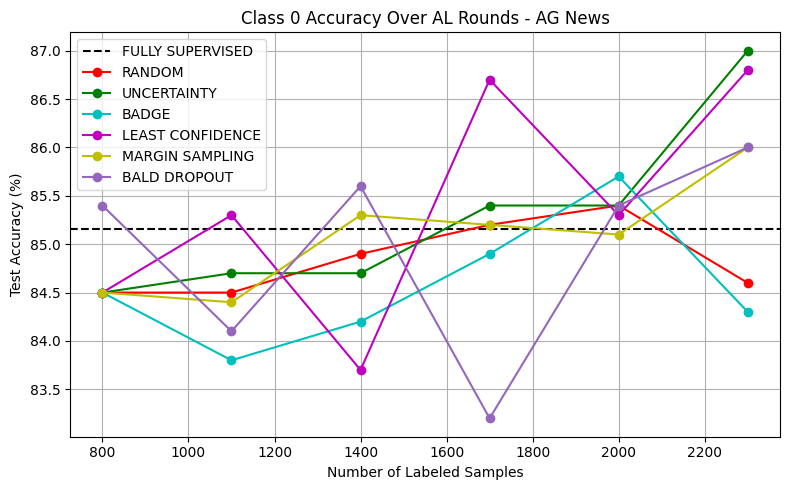

Missing file: results/AGN/baseline/class_1_FASS.txt
Missing file: results/AGN/baseline/class_1_CoreSet.txt
Missing file: results/AGN/baseline/class_1_AdversarialDeepFool.txt


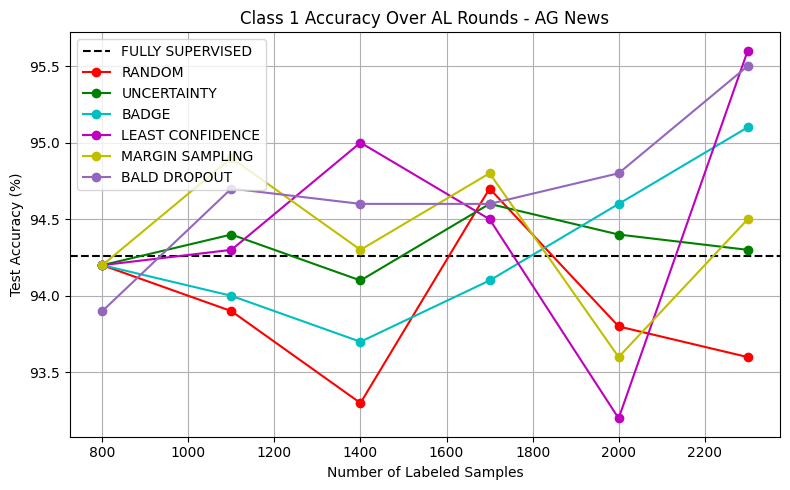

Missing file: results/AGN/baseline/class_2_FASS.txt
Missing file: results/AGN/baseline/class_2_CoreSet.txt
Missing file: results/AGN/baseline/class_2_AdversarialDeepFool.txt


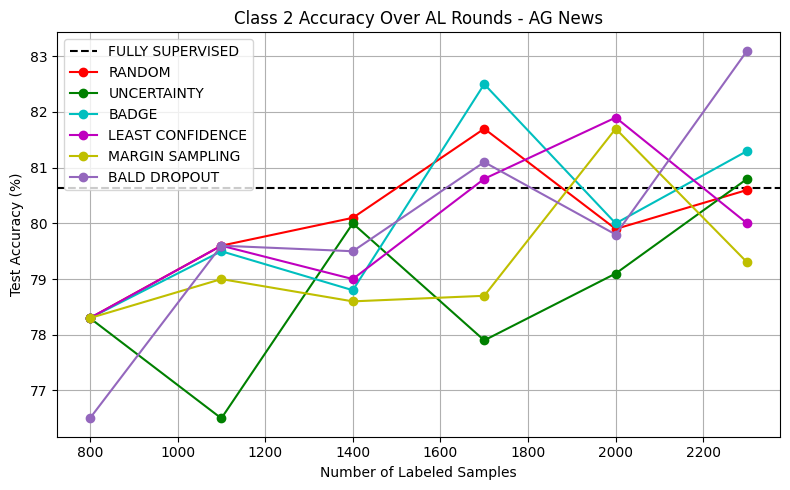

Missing file: results/AGN/baseline/class_3_FASS.txt
Missing file: results/AGN/baseline/class_3_CoreSet.txt
Missing file: results/AGN/baseline/class_3_AdversarialDeepFool.txt


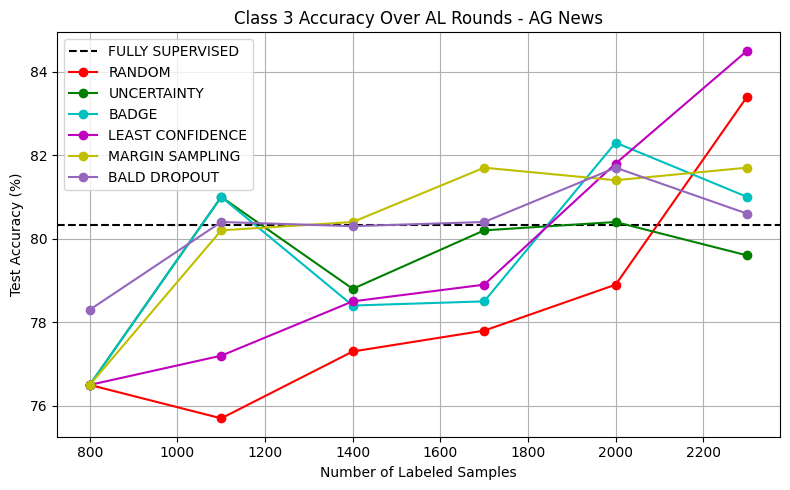

In [52]:
import os
import numpy as np
import matplotlib.pyplot as plt

# Directory with accuracy result files
dir = os.path.join('results', 'AGN', 'baseline')

# Define AL experiment parameters
print(train_size_pc)
x_axis = np.array([(train_size_pc * 4) + budget * i for i in range(n_rounds)])

# Strategies to compare (extended)
strategies = [
    'random', 'entropy', 'badge', 'leastConfidence', 'marginSampling',
    'FASS', 'CoreSet', 'BALDDropout', 'AdversarialDeepFool'
]

# Color map (ensure unique and distinguishable colors)
colors = {
    'random': 'r',
    'entropy': 'g',
    'badge': 'c',
    'leastConfidence': 'm',
    'marginSampling': 'y',
    'FASS': 'tab:blue',
    'CoreSet': 'tab:orange',
    'BALDDropout': 'tab:purple',
    'AdversarialDeepFool': 'tab:pink'
}

# Human-readable labels
labels = {
    'random': 'RANDOM',
    'entropy': 'UNCERTAINTY',
    'badge': 'BADGE',
    'leastConfidence': 'LEAST CONFIDENCE',
    'marginSampling': 'MARGIN SAMPLING',
    'FASS': 'FASS',
    'CoreSet': 'CORESET',
    'BALDDropout': 'BALD DROPOUT',
    'AdversarialDeepFool': 'ADV. DEEPFOOL'
}

# Plot per-class accuracy curves
for cls in range(nclasses):
    plt.figure(figsize=(8, 5))

    # Load fully supervised baseline
    full_sup_file = os.path.join(dir, f'class_{cls}_fully_supervised.txt')
    if os.path.exists(full_sup_file):
        with open(full_sup_file, 'r') as f:
            ref_acc = round(float(f.read().strip()) * 100, 2)
            plt.axhline(y=ref_acc, color='k', linestyle='--', label='FULLY SUPERVISED')

    for strat in strategies:
        file_path = os.path.join(dir, f'class_{cls}_{strat}.txt')
        if not os.path.exists(file_path):
            print(f"Missing file: {file_path}")
            continue

        with open(file_path, 'r') as f:
            acc_list = [round(float(line.strip()) * 100, 2) for line in f]
            plt.plot(x_axis, acc_list, label=labels[strat], marker='o', color=colors.get(strat, 'gray'))

    plt.title(f'Class {cls} Accuracy Over AL Rounds - AG News')
    plt.xlabel('Number of Labeled Samples')
    plt.ylabel('Test Accuracy (%)')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


Visualize metrics

In [53]:
import os
import pandas as pd
from glob import glob

def load_all_strategies(result_files):
    all_results = {}
    for path in result_files:
        strategy_name = os.path.basename(path).replace('_evaluation_summary_', '').replace('.csv', '')
        df = pd.read_csv(path)
        df.set_index('Class', inplace=True)
        all_results[strategy_name] = df[['AUC', 'LabelSaving']]
    return all_results

def generate_latex_table(all_results, output_path):
    strategy_names = sorted(all_results.keys())
    class_ids = sorted(next(iter(all_results.values())).index.tolist())

    latex = r"""\documentclass{article}
\usepackage{booktabs}
\usepackage{graphicx}
\usepackage[margin=1in]{geometry}
\begin{document}

\begin{table}[h!]
\centering
\scriptsize
\begin{tabular}{c""" + "cc" * len(strategy_names) + "}\n"
    latex += r"\toprule" + "\n"
    latex += "Class "
    for s in strategy_names:
        latex += f"& {s.capitalize()} AUC & {s.capitalize()} Saving "
    latex += r"\\ \midrule" + "\n"

    for class_id in class_ids:
        row = f"{class_id} "
        aucs = {s: all_results[s].loc[class_id, 'AUC'] for s in strategy_names}
        saves = {s: all_results[s].loc[class_id, 'LabelSaving'] for s in strategy_names}

        best_auc = max(aucs.values())
        best_save = max(saves.values())

        for s in strategy_names:
            auc = aucs[s]
            save = saves[s]
            auc_str = f"\\textbf{{{auc:.2f}}}" if auc == best_auc else f"{auc:.2f}"
            save_str = f"\\textbf{{{save:.2f}}}" if save == best_save else f"{save:.2f}"
            row += f"& {auc_str} & {save_str} "
        latex += row + r"\\" + "\n"

    latex += r"""\bottomrule
\end{tabular}
\caption{Comparison of AUC and label saving per class across active learning strategies. Best values per class are in bold.}
\label{tab:auc_label_saving}
\end{table}

\end{document}
"""

    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    with open(output_path, "w") as f:
        f.write(latex)
    print(f"LaTeX table saved to {output_path}")




# Point to your directory where results are stored
result_files = glob('results/AGN/baseline/evaluation_summary_*.csv')

# Load and generate LaTeX
all_results = load_all_strategies(result_files)
generate_latex_table(all_results, 'results/AGN/baseline/comparison_table.tex')


LaTeX table saved to results/AGN/baseline/comparison_table.tex


In [56]:
from collections import Counter

# Count labels in the unlabeled set
unlabeled_labels = [training_dataset[i]['labels'].item() for i in full_unlabeled_subset]
class_counts = Counter(unlabeled_labels)

print("Class distribution in unlabeled dataset:")
for cls in range(nclasses):
    print(f"Class {cls}: {class_counts[cls]} samples")

Class distribution in unlabeled dataset:
Class 0: 5000 samples
Class 1: 5000 samples
Class 2: 5000 samples
Class 3: 5000 samples
